# Chess Games Analysis (Lichess Dataset)

This project explores a dataset of online chess games to understand what factors influence game outcomes.

The focus here is mainly exploratory:
- Understanding how rating differences relate to results
- Looking at distributions rather than building a predictive model (for now)

The goal is to build intuition about the data before moving into more advanced modeling.


## Initial Data Exploration

Here I load and inspect the dataset to understand its structure, available features, and potential limitations.

This step helps avoid making incorrect assumptions later in the analysis.


In [1]:
import pandas as pd
import numpy as np

## General Info

This is a set of just over 20,000 games collected from a selection of users on the site Lichess.org, and how to collect more. I will also upload more games in the future as I collect them. This set contains the:

    Game ID;
    Rated (T/F);
    Start Time;
    End Time;
    Number of Turns;
    Game Status;
    Winner;
    Time Increment;
    White Player ID;
    White Player Rating;
    Black Player ID;
    Black Player Rating;
    All Moves in Standard Chess Notation;
    Opening Eco (Standardised Code for any given opening, list here);
    Opening Name;
    Opening Ply (Number of moves in the opening phase)


In [2]:
data = pd.read_csv("./games.csv")

display(data)
print(data.columns.values)

,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
0,TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5
1,l1NXvwaE,True,1.504130e+12,1.504130e+12,16,resign,black,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,Nimzowitsch Defense: Kennedy Variation,4
2,mIICvQHh,True,1.504130e+12,1.504130e+12,61,mate,white,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,King's Pawn Game: Leonardis Variation,3
3,kWKvrqYL,True,1.504110e+12,1.504110e+12,61,mate,white,20+0,daniamurashov,1439,adivanov2009,1454,d4 d5 Nf3 Bf5 Nc3 Nf6 Bf4 Ng4 e3 Nc6 Be2 Qd7 O...,D02,Queen's Pawn Game: Zukertort Variation,3
4,9tXo1AUZ,True,1.504030e+12,1.504030e+12,95,mate,white,30+3,nik221107,1523,adivanov2009,1469,e4 e5 Nf3 d6 d4 Nc6 d5 Nb4 a3 Na6 Nc3 Be7 b4 N...,C41,Philidor Defense,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20053,EfqH7VVH,True,1.499791e+12,1.499791e+12,24,resign,white,10+10,belcolt,1691,jamboger,1220,d4 f5 e3 e6 Nf3 Nf6 Nc3 b6 Be2 Bb7 O-O Be7 Ne5...,A80,Dutch Defense,2
20054,WSJDhbPl,True,1.499698e+12,1.499699e+12,82,mate,black,10+0,jamboger,1233,farrukhasomiddinov,1196,d4 d6 Bf4 e5 Bg3 Nf6 e3 exd4 exd4 d5 c3 Bd6 Bd...,A41,Queen's Pawn,2
20055,yrAas0Kj,True,1.499698e+12,1.499698e+12,35,mate,white,10+0,jamboger,1219,schaaksmurf3,1286,d4 d5 Bf4 Nc6 e3 Nf6 c3 e6 Nf3 Be7 Bd3 O-O Nbd...,D00,Queen's Pawn Game: Mason Attack,3
20056,b0v4tRyF,True,1.499696e+12,1.499697e+12,109,resign,white,10+0,marcodisogno,1360,jamboger,1227,e4 d6 d4 Nf6 e5 dxe5 dxe5 Qxd1+ Kxd1 Nd5 c4 Nb...,B07,Pirc Defense,4


<StringArray>
[            'id',          'rated',     'created_at',   'last_move_at',
          'turns', 'victory_status',         'winner', 'increment_code',
       'white_id',   'white_rating',       'black_id',   'black_rating',
          'moves',    'opening_eco',   'opening_name',    'opening_ply']
Length: 16, dtype: str


,victory_status,winner,opening_ply
0,outoftime,white,5
1,resign,black,4
2,mate,white,3
3,mate,white,3
4,mate,white,5
...,...,...,...
20053,resign,white,2
20054,mate,black,2
20055,mate,white,3
20056,resign,white,4


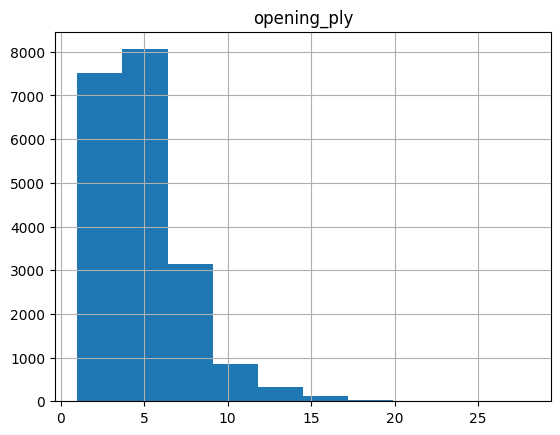

In [3]:
selected_columns=['victory_status', 'winner', 'opening_ply']
sd = data[selected_columns].copy()
display(sd)

sd.hist()
sd['winner'] = sd['winner'].map({'white': 1, 'black': 0, 'draw': 0.5})


## Visual Analysis

Here I use plots to understand how rating differences relate to game outcomes.

Visualizations help reveal patterns that are not obvious from raw numbers, such as overlap between classes or skewed distributions.


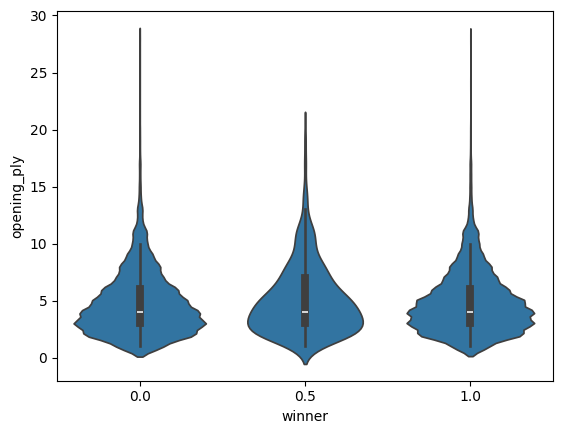

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.violinplot(data=sd, x='winner', y='opening_ply')
plt.show()

## Rating Differential

## Feature Engineering

I create a new variable `rating_diff` to simplify comparison between players.

Instead of analyzing two separate ratings, this captures the relative strength difference:
- Positive → White is stronger
- Negative → Black is stronger

This is likely one of the most important variables for explaining outcomes.


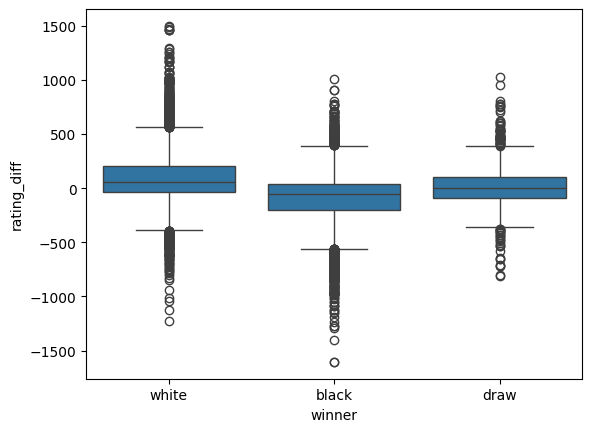

In [5]:
data['rating_diff'] = data['white_rating'] - data['black_rating']

sns.boxplot(data=data, x='winner', y='rating_diff')
plt.show()

## Conclusions

The median rating difference is slightly positive for white wins and slightly negative for black wins, indicating that the winning player is typically the higher-rated player.

Draws have a median rating difference close to zero, suggesting they occur more frequently between players of similar rating.

Overall, the game outcomes are consistent with rating differences: higher rated players tend to win more often, while the even rated players tend to draw.

## Heatmap for all relevant features

At first I used Pearson linear correlation, which for the current dataset is not a good approach, since:
- 'winner' column is arbitrary binary encoded, for which Pearson tries to find a linear relationship

Here, Spearman or Kendall correlation will be better since they are more sensitive to magnitude differences and offer higher robustness to outliers

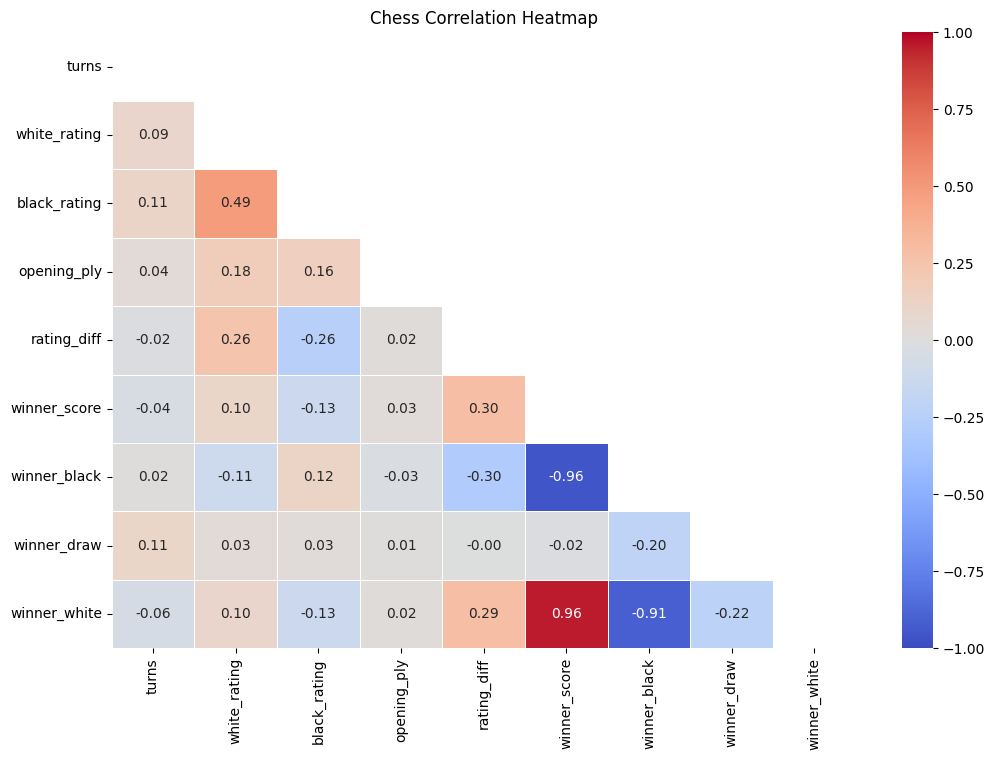

count    20058.000000
mean       173.091435
std        179.214854
min          0.000000
25%         45.000000
50%        115.000000
75%        241.000000
max       1605.000000
Name: rating_diff, dtype: float64

In [6]:
drop_cols=['id', 'last_move_at', 'created_at']
hd = data.drop(columns=drop_cols).copy()

hd['rating_diff'] = hd['white_rating'] - hd['black_rating']
hd['winner_score'] = hd['winner'].map({'white': 1, 'black': 0, 'draw': 0.5})

hd_copy = hd.copy()

winner_dummies = pd.get_dummies(data['winner'], prefix='winner', dtype=int)
hd = pd.concat([hd, winner_dummies], axis=1)

correlation_matrix = hd.select_dtypes(include=['number']).corr(method='kendall')

plt.figure(figsize=(12, 8))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(
    correlation_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap='coolwarm', 
    mask=mask, 
    linewidths=0.5, 
    vmin=-1, 
    vmax=1
)

plt.title("Chess Correlation Heatmap")
plt.show()

hd['rating_diff'].abs().describe()

## Point-Biserial Correlation

Because the winner variable is categorical (0, 0.5, 1) the correlation might be weak.

Therefore, using point-biserial correlation will be a better indicator since it determines if the relation between binary variable ('winner_score') and continuous variable ('rating_diff') is statistically significant.

In [7]:
from scipy import stats

coef, p_value = stats.pointbiserialr(hd_copy['rating_diff'], hd_copy['winner_score'])

print(f"Correlation: {coef:.4f}")
print(f"P-value: {p_value:.4f}")

Correlation: 0.3607
P-value: 0.0000


## Conclusions

- Since the correlation between rating difference and winner_score is 0.36 and it is statistically significant, we can see that rating difference is a solid indicator of the winner. Yet it being lower than 1.0 leaves a lot of room for the higher rated players to lose to blunders and other mistakes.
- The amount of opening book moves has close to no correleation to the outcome of the game
- Moderate correlation between white's and black's rating suggest certain level of skill-based matchmaking

## Openings visualization

Visualization of top 10 most commonly played openings and their corresponding win rate

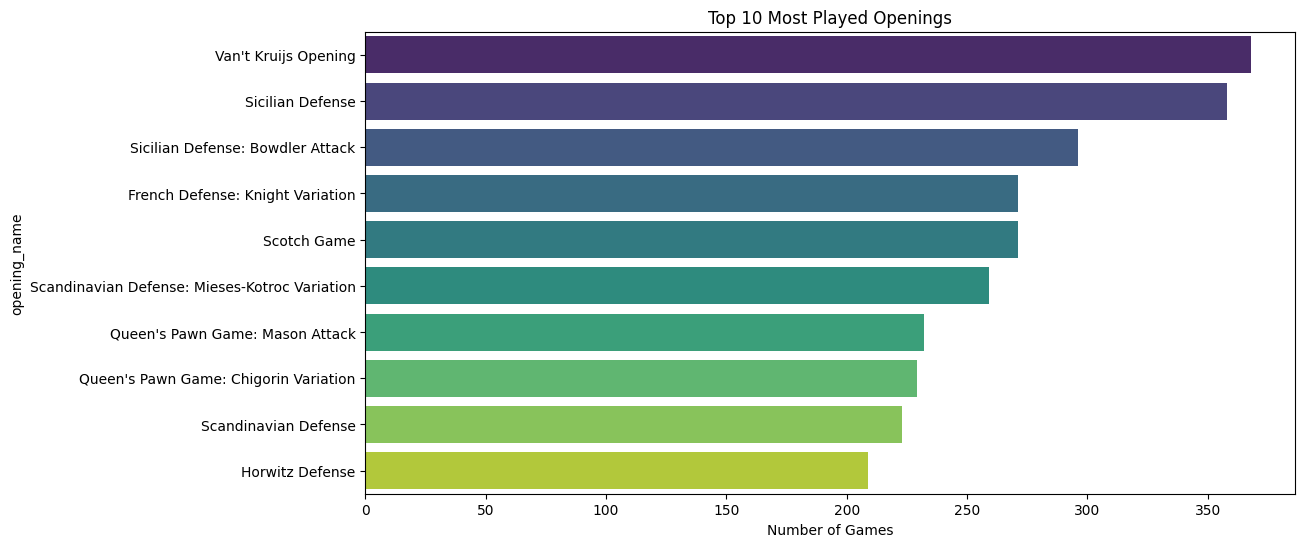

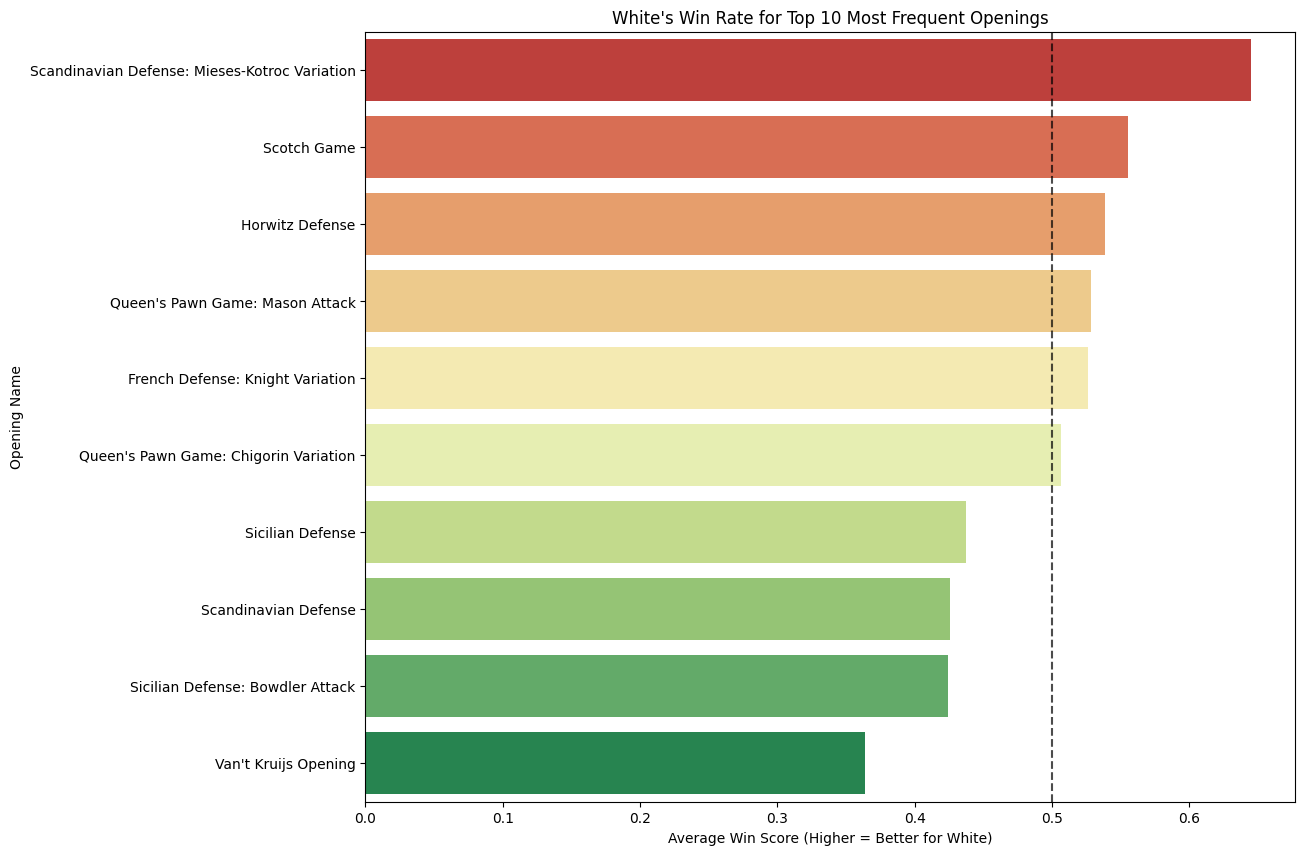

In [8]:
top_openings = data['opening_name'].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_openings.values, y=top_openings.index, palette='viridis',
           hue=top_openings.index, legend=False)
plt.title('Top 10 Most Played Openings')
plt.xlabel('Number of Games')
plt.show()

win_openings = data['opening_name'].value_counts().nlargest(10).index
top_df = data[data['opening_name'].isin(win_openings)].copy()

top_df['win_score'] = top_df['winner'].map({'white': 1, 'black': 0, 'draw': 0.5})

win_rates = top_df.groupby('opening_name')['win_score'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 10))
sns.barplot(
    x=win_rates.values, 
    y=win_rates.index, 
    hue=win_rates.index, 
    palette='RdYlGn', 
    legend=False
)

plt.axvline(0.5, color='black', linestyle='--', alpha=0.7)

plt.title("White's Win Rate for Top 10 Most Frequent Openings")
plt.xlabel("Average Win Score (Higher = Better for White)")
plt.ylabel("Opening Name")
plt.show()



In [9]:
new_df = data.copy()

bins = [0, 1200, 1800, 4000]
labels = ['Beginner', 'Intermediate', 'Advanced']
rating = (new_df['white_rating'] + new_df['black_rating']) / 2
new_df['skill_level'] = pd.cut(rating, bins=bins, labels=labels)

drop_cols = ['id', 'created_at', 'last_move_at', 'white_rating', 'black_rating', 
            'moves', 'opening_eco', 'white_id', 'black_id']
new_df = new_df.drop(columns=drop_cols)


display(new_df)

,rated,turns,victory_status,winner,increment_code,opening_name,opening_ply,rating_diff,skill_level
0,False,13,outoftime,white,15+2,Slav Defense: Exchange Variation,5,309,Intermediate
1,True,16,resign,black,5+10,Nimzowitsch Defense: Kennedy Variation,4,61,Intermediate
2,True,61,mate,white,5+10,King's Pawn Game: Leonardis Variation,3,-4,Intermediate
3,True,61,mate,white,20+0,Queen's Pawn Game: Zukertort Variation,3,-15,Intermediate
4,True,95,mate,white,30+3,Philidor Defense,5,54,Intermediate
...,...,...,...,...,...,...,...,...,...
20053,True,24,resign,white,10+10,Dutch Defense,2,471,Intermediate
20054,True,82,mate,black,10+0,Queen's Pawn,2,37,Intermediate
20055,True,35,mate,white,10+0,Queen's Pawn Game: Mason Attack,3,-67,Intermediate
20056,True,109,resign,white,10+0,Pirc Defense,4,133,Intermediate


In [10]:
print(new_df['victory_status'].value_counts())
print(new_df['increment_code'])

victory_status
resign       11147
mate          6325
outoftime     1680
draw           906
Name: count, dtype: int64
0         15+2
1         5+10
2         5+10
3         20+0
4         30+3
         ...  
20053    10+10
20054     10+0
20055     10+0
20056     10+0
20057     10+0
Name: increment_code, Length: 20058, dtype: str


In [11]:
new_df['base_time'] = new_df['increment_code'].str.split('+').str[0].astype(int)
print(new_df[['increment_code', 'base_time']].head())

time_bins = [-1, 2, 9, 29, 500]
time_labels = ['Bullet', 'Blitz', 'Rapid', 'Classical']

new_df['time_category'] = pd.cut(new_df['base_time'], bins=time_bins, labels=time_labels)
print(new_df['time_category'].value_counts())

  increment_code  base_time
0           15+2         15
1           5+10          5
2           5+10          5
3           20+0         20
4           30+3         30
time_category
Rapid        14709
Blitz         3939
Classical     1279
Bullet         131
Name: count, dtype: int64


In [12]:
new_df = new_df.drop(columns=['base_time', 'increment_code'])
display(new_df)


,rated,turns,victory_status,winner,opening_name,opening_ply,rating_diff,skill_level,time_category
0,False,13,outoftime,white,Slav Defense: Exchange Variation,5,309,Intermediate,Rapid
1,True,16,resign,black,Nimzowitsch Defense: Kennedy Variation,4,61,Intermediate,Blitz
2,True,61,mate,white,King's Pawn Game: Leonardis Variation,3,-4,Intermediate,Blitz
3,True,61,mate,white,Queen's Pawn Game: Zukertort Variation,3,-15,Intermediate,Rapid
4,True,95,mate,white,Philidor Defense,5,54,Intermediate,Classical
...,...,...,...,...,...,...,...,...,...
20053,True,24,resign,white,Dutch Defense,2,471,Intermediate,Rapid
20054,True,82,mate,black,Queen's Pawn,2,37,Intermediate,Rapid
20055,True,35,mate,white,Queen's Pawn Game: Mason Attack,3,-67,Intermediate,Rapid
20056,True,109,resign,white,Pirc Defense,4,133,Intermediate,Rapid


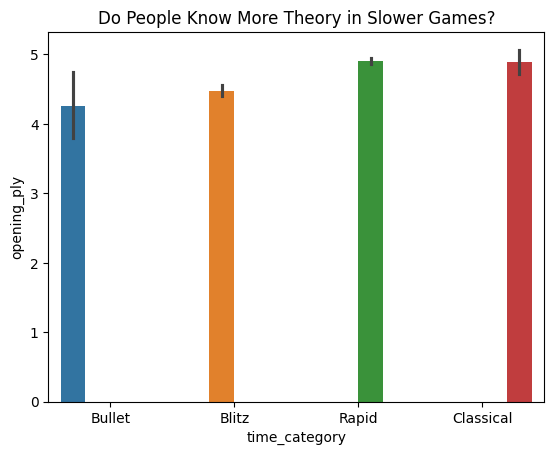

In [13]:
sns.barplot(data=new_df, x='time_category', y='opening_ply', hue='time_category', legend=False)
plt.title("Do People Know More Theory in Slower Games?")
plt.show()

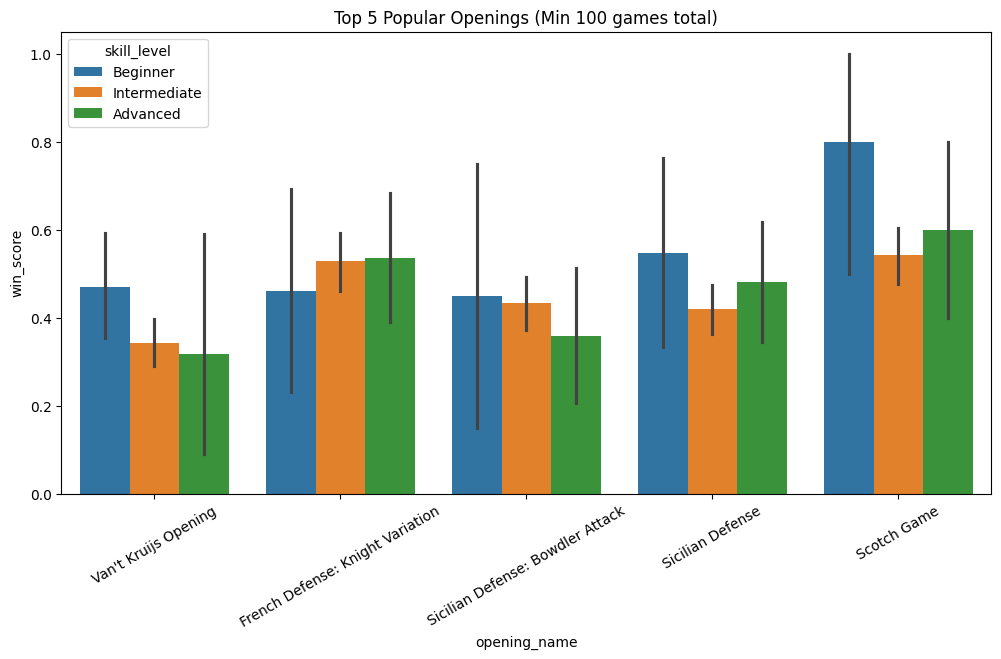

In [14]:
new_df['win_score'] = new_df['winner'].map({'white': 1, 'black': 0, 'draw': 0.5})

counts = new_df['opening_name'].value_counts()
valid_openings = counts[counts >= 100].index

filtered_df = new_df[new_df['opening_name'].isin(valid_openings)]
top_5 = filtered_df['opening_name'].value_counts().nlargest(5).index
subset = filtered_df[filtered_df['opening_name'].isin(top_5)]

# Plotting
plt.figure(figsize=(12, 6))
sns.barplot(data=subset, x='opening_name', y='win_score', hue='skill_level')
plt.xticks(rotation=30)
plt.title("Top 5 Popular Openings (Min 100 games total)")
plt.show()

## Black's best response to 1. e4

Checking for black's best defense move in the opening against e4 for games played minimum of 30 times

,response,black_win_rate,game_count
8,c5,0.519954,2581
7,b6,0.500000,177
13,e6,0.487047,1351
9,c6,0.486511,556
17,g6,0.482857,175


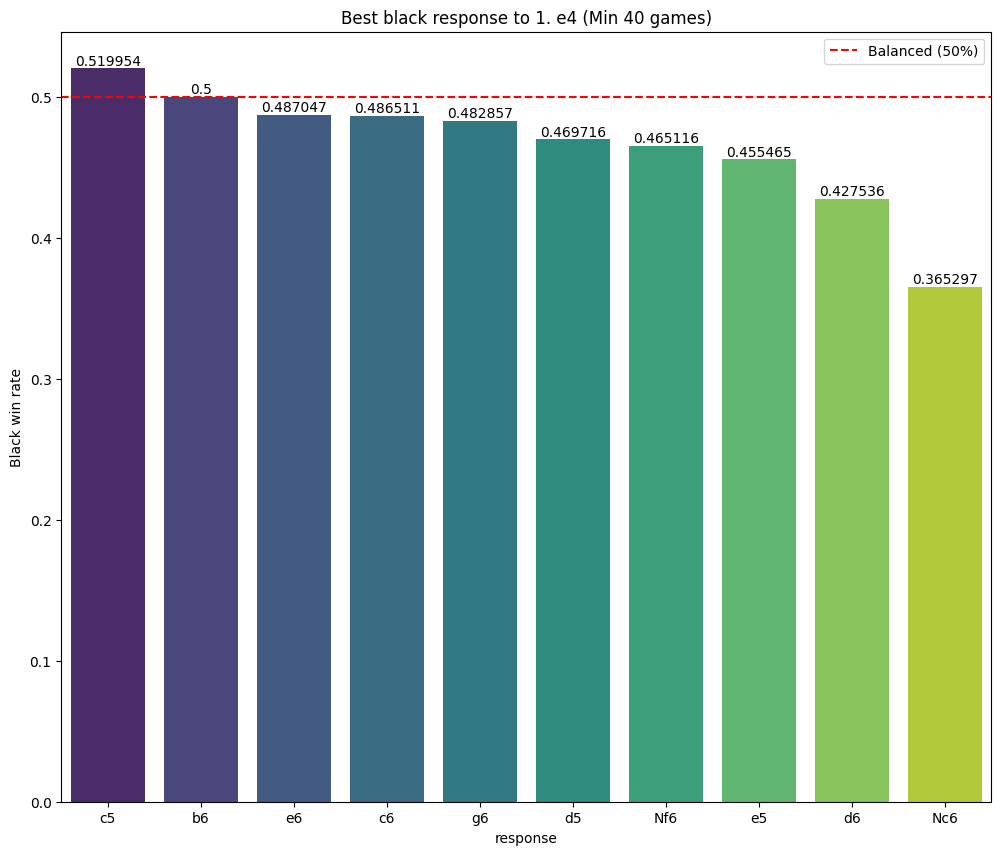

In [15]:
df = new_df.copy()
df['moves'] = data['moves']

df['first_move'] = df['moves'].str.split().str[0]
response_move = df['moves'].str.split().str[1]
df['response'] = response_move
first_move = 'e4'

e4_games = df[df['first_move'] == first_move].copy()
e4_games['black_win_score'] = 1 - e4_games['win_score']
e4_games = e4_games.drop(columns='win_score')

level_df = e4_games.copy()

response_stats = e4_games.groupby('response').agg(
    black_win_rate = ('black_win_score', 'mean'),
    game_count = ('black_win_score', 'count')
).reset_index()

top_responses = response_stats[response_stats['game_count'] >= 40].sort_values('black_win_rate' ,ascending=False)

display(top_responses.head())

plt.figure(figsize=(12,10))
ax = sns.barplot(data=top_responses, x='response', y='black_win_rate', palette = 'viridis', hue='response')
plt.axhline(0.5, color='red', linestyle='--', label='Balanced (50%)')
plt.title('Best black response to 1. e4 (Min 40 games)')
plt.ylabel('Black win rate')
for container in ax.containers:
    ax.bar_label(container)
plt.legend()
plt.show()

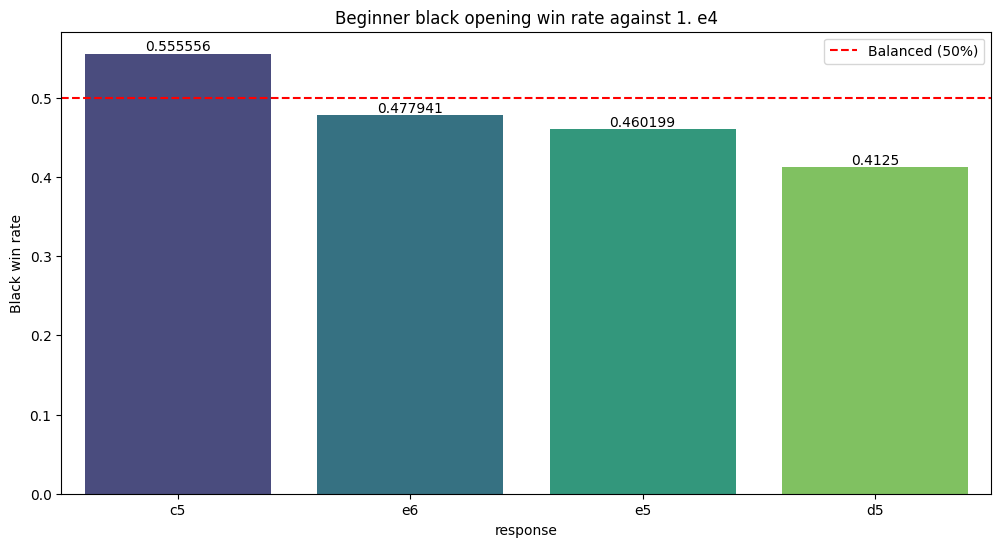

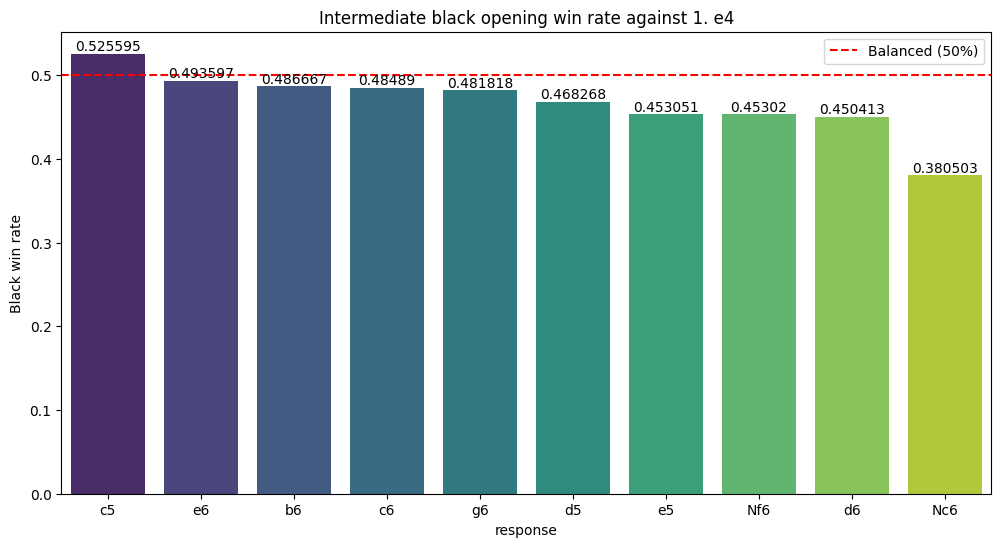

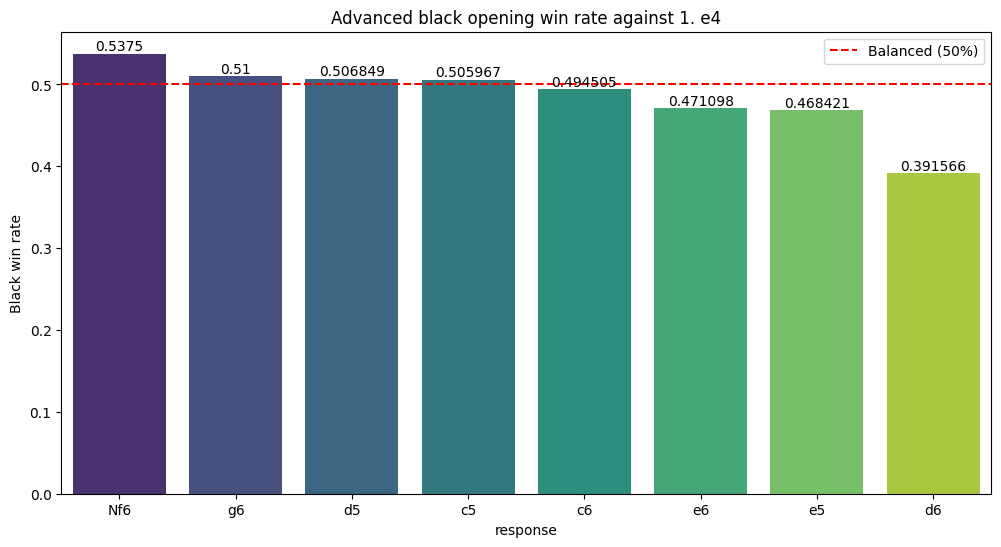

In [16]:
response_stats = level_df.groupby(['response', 'skill_level'], observed=False).agg(
    black_win_rate = ('black_win_score', 'mean'),
    game_count = ('black_win_score', 'count')
).reset_index()

beginner_responses = response_stats[(response_stats['game_count'] >= 40) & 
    (response_stats['skill_level'] == 'Beginner')].sort_values('black_win_rate' ,ascending=False)

intermediate_responses = response_stats[(response_stats['game_count'] >= 40) & 
    (response_stats['skill_level'] == 'Intermediate')].sort_values('black_win_rate' ,ascending=False)

advanced_responses = response_stats[(response_stats['game_count'] >= 40) & 
    (response_stats['skill_level'] == 'Advanced')].sort_values('black_win_rate' ,ascending=False)

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=beginner_responses, x='response', y='black_win_rate', palette = 'viridis', hue='response')
plt.axhline(0.5, color='red', linestyle='--', label='Balanced (50%)')
plt.title('Beginner black opening win rate against 1. e4')
plt.ylabel('Black win rate')
for container in ax.containers:
    ax.bar_label(container)
plt.legend()
plt.show()

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=intermediate_responses, x='response', y='black_win_rate', palette = 'viridis', hue='response')
plt.axhline(0.5, color='red', linestyle='--', label='Balanced (50%)')
plt.title('Intermediate black opening win rate against 1. e4')
plt.ylabel('Black win rate')
for container in ax.containers:
    ax.bar_label(container)
plt.legend()
plt.show()

plt.figure(figsize=(12, 6))
ax = sns.barplot(data=advanced_responses, x='response', y='black_win_rate', palette = 'viridis', hue='response')
plt.axhline(0.5, color='red', linestyle='--', label='Balanced (50%)')
plt.title('Advanced black opening win rate against 1. e4')
plt.ylabel('Black win rate')
for container in ax.containers:
    ax.bar_label(container)
plt.legend()
plt.show()

In [17]:
display(advanced_responses[advanced_responses['response'].isin(['Nf6', 'g6'])])

,response,skill_level,black_win_rate,game_count
8,Nf6,Advanced,0.5375,40
53,g6,Advanced,0.5100,50


## Conclusions

We can see that on all levels Sicilian Defense (2. c5) is an effective defense move against 1. e4.
It's win rate is very high among beginner players (~55%) and high for intermediate players (~52.5%), whereas close to 50% for the advanced ones.
For beginner and intermediate players in this sample it was the only effective response.

For advanced players (>1800 elo) 2. Nf6 Alekhine's defense has a very high win rate above 53%, however, the game count for this defense is only 40, since it is not a commonly played defense.
Other responses are close or below 50% win rate, with only modern defense standing out with exactly 51% win rate in 50 games played.

## Do pros resign more often than beginners

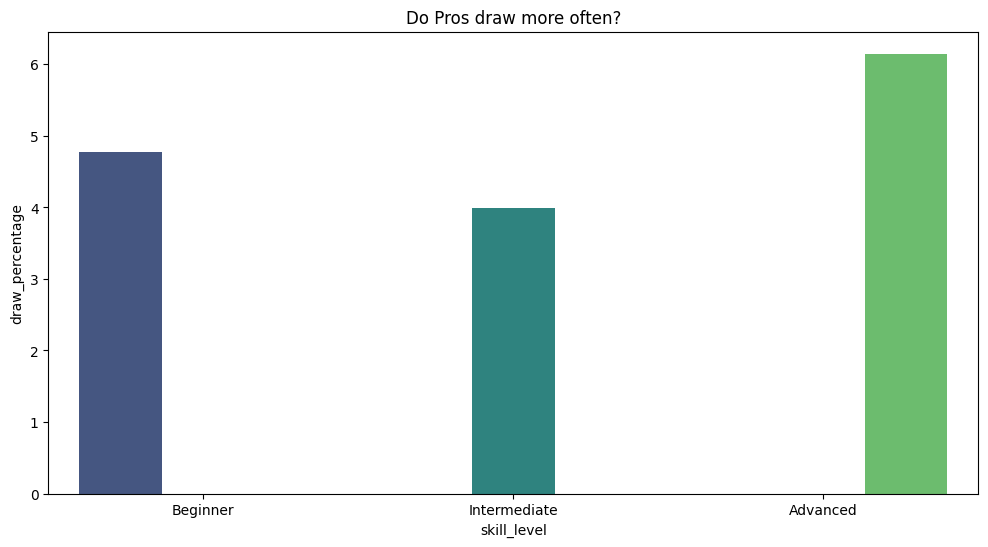

,skill_level,total_games,draw_count,draw_percentage
0,Beginner,1173,56,4.774084
1,Intermediate,14429,576,3.991961
2,Advanced,4456,274,6.149013


In [18]:
draw_df = new_df.copy()

draw_df = draw_df.groupby('skill_level', observed=False).agg(
    total_games = ('victory_status', 'count'),
    draw_count = ('victory_status', lambda x: (x == 'draw').sum())
).reset_index()

draw_df['draw_percentage'] = (draw_df['draw_count'] / draw_df['total_games']) * 100

plt.figure(figsize=(12,6))
sns.barplot(data=draw_df, x='skill_level', y='draw_percentage', palette='viridis', hue='skill_level')
plt.title('Do Pros draw more often?')
plt.show()

display(draw_df)

## Conculsions

Players with elo classified as advanced are more likely to end their games with a draw

## Conclusions (Revised)

- Rating difference clearly correlates with outcome, which is expected since ratings are designed to reflect player strength.
- There is still noticeable overlap between winners and losers, meaning the stronger player does not always win.
- Draws appear more frequently when rating differences are small, suggesting more balanced matchups.

At the same time, this analysis is limited:
- It relies heavily on a single engineered feature
- The insights are somewhat expected rather than surprising

### Next steps to improve:
- Add more features (openings, game length, time controls)
- Investigate upset games (when lower-rated players win)
- Move toward building a predictive model

This project is a solid starting point, but it needs deeper analysis to stand out.


# Part 2 — Extended Analysis

The first part of this notebook explored rating difference, openings and skill levels. The "next steps" at the end of Part 1 were: *add more features (openings, game length, time controls)* and *investigate upset games*. Part 2 does that, adds proper statistical testing (confidence intervals, hypothesis tests, effect sizes), and finishes by exporting a clean **star-schema dataset for Tableau**.

**Sections**
1. Data quality audit and cleaning
2. Descriptive statistics
3. Overall outcomes and the white-advantage test
4. How games end (victory status)
5. Do Elo ratings predict results? (calibration)
6. Upsets
7. Time controls
8. Game length
9. Openings with confidence intervals
10. Player-level analysis
11. Activity over time
12. Predictive model (logistic regression)
13. Key findings
14. Export for Tableau

## 1. Data quality audit and cleaning

Before computing any new statistics I check the data itself. Everything below this point uses the **de-duplicated** dataset (`clean`).

In [19]:
from scipy import stats
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

raw = pd.read_csv('./games.csv')

audit = pd.Series({
    'rows': len(raw),
    'columns': raw.shape[1],
    'missing values (total)': int(raw.isna().sum().sum()),
    'duplicate game ids': int(raw['id'].duplicated().sum()),
    'duplicate (id + moves)': int(raw.duplicated(subset=['id', 'moves']).sum()),
    'games with created_at == last_move_at': int((raw['created_at'] == raw['last_move_at']).sum()),
    'games with <= 10 turns': int((raw['turns'] <= 10).sum()),
}, name='value')
display(audit.to_frame())

# How much did the duplicates distort the "most active players" ranking?
def games_per_player(df):
    return pd.concat([df['white_id'], df['black_id']]).value_counts()
before, after = games_per_player(raw), games_per_player(raw.drop_duplicates('id'))
cmp_ = pd.DataFrame({'games_raw': before, 'games_deduped': after}).fillna(0).astype(int)
cmp_['phantom_games'] = cmp_['games_raw'] - cmp_['games_deduped']
display(cmp_.sort_values('phantom_games', ascending=False).head(5))

,value
rows,20058
columns,16
missing values (total),0
duplicate game ids,945
duplicate (id + moves),945
games with created_at == last_move_at,8548
games with <= 10 turns,681


,games_raw,games_deduped,phantom_games
taranga,154,49,105
a_p_t_e_m_u_u,96,41,55
vladimir-kramnik-1,96,48,48
chess-brahs,65,21,44
king5891,78,39,39


**What the audit shows**
- There are no missing values, which is good.
- **945 rows (4.7%) are duplicates** of another game (same `id` and same `moves`; they differ only by timestamps). Part 1 counted these twice. The distortion is much bigger at player level: the most active player, `taranga`, shows 154 games in the raw file but only 49 real ones. All duplicates are removed below.
- About 43% of games have `created_at == last_move_at`, so **game duration cannot be measured reliably** from this data. I use number of turns as the measure of game length instead.
- `created_at` stretches back to 2013 but most games are from 2017, with a big spike in Aug 2017. Any time-trend conclusions need that caveat.

In [20]:
clean = raw.drop_duplicates(subset=['id']).copy().reset_index(drop=True)

# --- timestamps ---
clean['created_dt'] = pd.to_datetime(clean['created_at'], unit='ms')
clean['year'] = clean['created_dt'].dt.year
clean['month'] = clean['created_dt'].dt.to_period('M').dt.to_timestamp()
clean['hour_utc'] = clean['created_dt'].dt.hour
clean['weekday'] = clean['created_dt'].dt.day_name()

# --- engineered features ---
clean['rating_diff'] = clean['white_rating'] - clean['black_rating']          # + = white is higher rated
clean['abs_rating_diff'] = clean['rating_diff'].abs()
clean['avg_rating'] = (clean['white_rating'] + clean['black_rating']) / 2
clean['white_score'] = clean['winner'].map({'white': 1, 'black': 0, 'draw': 0.5})
clean['higher_rated_color'] = np.select([clean['rating_diff'] > 0, clean['rating_diff'] < 0], ['white', 'black'], 'equal')

clean['skill_level'] = pd.cut(clean['avg_rating'], [0, 1200, 1800, 4000], labels=['Beginner', 'Intermediate', 'Advanced'])

inc = clean['increment_code'].str.split('+', expand=True).astype(int)
clean['base_minutes'], clean['increment_sec'] = inc[0], inc[1]
clean['has_increment'] = np.where(clean['increment_sec'] > 0, 'With increment', 'No increment')
# Same base-time bands as Part 1 (Lichess's own duration-based labels would put ~100% of this dataset into Rapid/Classical)
clean['time_category'] = pd.cut(clean['base_minutes'], [-1, 2, 9, 29, 500], labels=['Bullet', 'Blitz', 'Rapid', 'Classical'])

clean['opening_family'] = clean['opening_name'].str.split(':').str[0].str.split('|').str[0].str.strip()
clean['eco_group'] = clean['opening_eco'].str[0]
eco_names = {'A': 'A - Flank openings', 'B': 'B - Semi-open (e4, not e5)', 'C': 'C - Open games (e4 e5) / French',
             'D': 'D - Closed / Queen\'s Gambit', 'E': 'E - Indian defences'}
clean['eco_group_name'] = clean['eco_group'].map(eco_names)
clean['first_move'] = clean['moves'].str.split().str[0]
clean['black_response'] = clean['moves'].str.split().str[1]
clean['is_upset'] = ((clean['rating_diff'] > 0) & (clean['winner'] == 'black')) | ((clean['rating_diff'] < 0) & (clean['winner'] == 'white'))
clean['decisive'] = clean['winner'] != 'draw'

print(f"Rows: {len(raw):,} -> {len(clean):,} after removing {len(raw)-len(clean):,} duplicates")
print()
print(clean['time_category'].value_counts().to_string())

Rows: 20,058 -> 19,113 after removing 945 duplicates

time_category
Rapid        14004
Blitz         3777
Classical     1209
Bullet         123


> **Note on time controls.** I keep the same base-time bands as Part 1: Bullet (up to 2 min), Blitz (3-9 min), Rapid (10-29 min) and Classical (30+ min). Lichess's own labels use estimated duration (base + 40 x increment), but with that rule roughly 99.98% of the games in this dataset fall into Rapid or Classical, which makes comparisons between categories meaningless. The increment is kept as a separate field (`has_increment`) so it can still be analysed.

## 2. Descriptive statistics

A full summary of the numeric variables, including skewness and kurtosis, followed by a check on whether ratings are normally distributed.

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
white_rating,19113.0,1597.30,290.02,784.0,1401.0,1567.0,1792.0,2700.0,0.29,0.02
black_rating,19113.0,1590.05,290.44,789.0,1394.0,1563.0,1785.0,2723.0,0.25,-0.06
avg_rating,19113.0,1593.67,262.54,816.5,1409.5,1570.0,1772.5,2475.5,0.26,-0.24
rating_diff,19113.0,7.25,247.44,-1605.0,-108.0,3.0,122.0,1499.0,0.07,2.94
turns,19113.0,60.51,33.49,1.0,37.0,55.0,79.0,349.0,0.88,1.18
opening_ply,19113.0,4.82,2.80,1.0,3.0,4.0,6.0,28.0,1.35,3.17


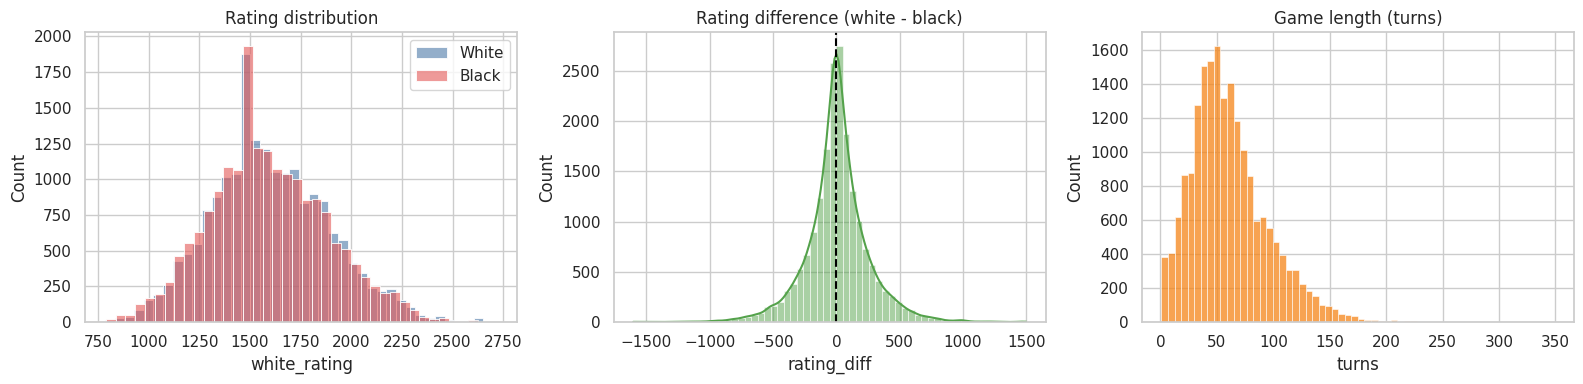

white_rating: skew=0.29, normality test p=4.54e-57
black_rating: skew=0.25, normality test p=3.24e-43


In [21]:
num_cols = ['white_rating', 'black_rating', 'avg_rating', 'rating_diff', 'turns', 'opening_ply']
desc = clean[num_cols].describe().T
desc['skew'] = clean[num_cols].skew()
desc['kurtosis'] = clean[num_cols].kurt()
display(desc.round(2))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(clean['white_rating'], bins=40, color='#4C78A8', label='White', alpha=.6, ax=ax[0])
sns.histplot(clean['black_rating'], bins=40, color='#E45756', label='Black', alpha=.6, ax=ax[0])
ax[0].set_title('Rating distribution'); ax[0].legend()
sns.histplot(clean['rating_diff'], bins=60, kde=True, color='#54A24B', ax=ax[1])
ax[1].axvline(0, color='black', ls='--'); ax[1].set_title('Rating difference (white - black)')
sns.histplot(clean['turns'], bins=60, color='#F58518', ax=ax[2]); ax[2].set_title('Game length (turns)')
plt.tight_layout(); plt.show()

# normality of ratings (D'Agostino-Pearson test)
for col in ['white_rating', 'black_rating']:
    k2, p = stats.normaltest(clean[col])
    print(f"{col}: skew={clean[col].skew():.2f}, normality test p={p:.2e}")

**Reading this:**
- Ratings are centred around 1590 with a standard deviation of about 290, and are only slightly right-skewed (skew about 0.3). With this many games the normality test rejects normality for even tiny deviations, so the skew value is the more useful number.
- `rating_diff` is symmetric around 0. Half of all games are within about ±115 points, but the tails run out to ±1500 (kurtosis about 3, i.e. heavier tails than a normal curve).
- `turns` is right-skewed: a few marathon games pull the mean (about 60) above the median (55).

## 3. Overall outcomes and the white-advantage test

Is white's first-move advantage real in this data or just noise? I estimate each outcome share with a 95% **Wilson confidence interval** and run an exact **binomial test** on decisive games (draws removed) against 50/50.

In [22]:
from statsmodels.stats.proportion import proportion_confint

n = len(clean)
rows = []
for res in ['white', 'black', 'draw']:
    k = (clean['winner'] == res).sum()
    lo, hi = proportion_confint(k, n, method='wilson')
    rows.append([res, k, k / n, lo, hi])
outcomes = pd.DataFrame(rows, columns=['result', 'games', 'share', 'ci_low', 'ci_high'])
display(outcomes.style.format({'share': '{:.1%}', 'ci_low': '{:.1%}', 'ci_high': '{:.1%}'}))

dec = clean[clean['decisive']]
k_w = (dec['winner'] == 'white').sum()
bt = stats.binomtest(k_w, len(dec), 0.5)
lo, hi = proportion_confint(k_w, len(dec), method='wilson')
print(f"Decisive games: {len(dec):,} | white wins {k_w/len(dec):.2%}  (95% CI {lo:.2%} - {hi:.2%})")
print(f"Exact binomial test vs 50%: p = {bt.pvalue:.2e}")

# does it depend on rated vs casual, and skill level?
by = lambda g: clean.groupby(g, observed=True).agg(games=('id', 'count'), white_win=('winner', lambda s: (s == 'white').mean()),
                                                    black_win=('winner', lambda s: (s == 'black').mean()), draw=('winner', lambda s: (s == 'draw').mean()))
display(by('rated').style.format('{:.1%}', subset=['white_win', 'black_win', 'draw']))
display(by('skill_level').style.format('{:.1%}', subset=['white_win', 'black_win', 'draw']))

,result,games,share,ci_low,ci_high
0,white,9545,49.9%,49.2%,50.6%
1,black,8680,45.4%,44.7%,46.1%
2,draw,888,4.6%,4.4%,5.0%


Decisive games: 18,225 | white wins 52.37%  (95% CI 51.65% - 53.10%)
Exact binomial test vs 50%: p = 1.54e-10


,games,white_win,black_win,draw
rated,,,,
False,3646,50.3%,44.1%,5.6%
True,15467,49.9%,45.7%,4.4%


,games,white_win,black_win,draw
skill_level,,,,
Beginner,1114,50.5%,44.4%,5.0%
Intermediate,13741,50.4%,45.4%,4.2%
Advanced,4258,48.2%,45.7%,6.1%


**Reading this:** White wins about 50% of all games vs about 45% for black, a gap of roughly 4.5 percentage points. Among decisive games white wins 52.4% (95% CI 51.7% to 53.1%), and the exact binomial test gives p of about 1.5e-10, so the first-move advantage is **statistically significant**. It is small in practical terms compared with the rating effect (next sections). Draws are rare overall (4.6%) but more common among Advanced players (about 6%) than Intermediate ones (about 4%). Rated and casual games look almost identical.

## 4. How games end (victory status)

Checking whether the way games end depends on skill level and time control, using a **chi-square test of independence** and **Cramér's V** as the effect size (0 = no association, 1 = perfect association).

skill_level: chi2=383.8, p=8.57e-80, Cramer's V=0.100


time_category: chi2=103.6, p=2.95e-18, Cramer's V=0.043


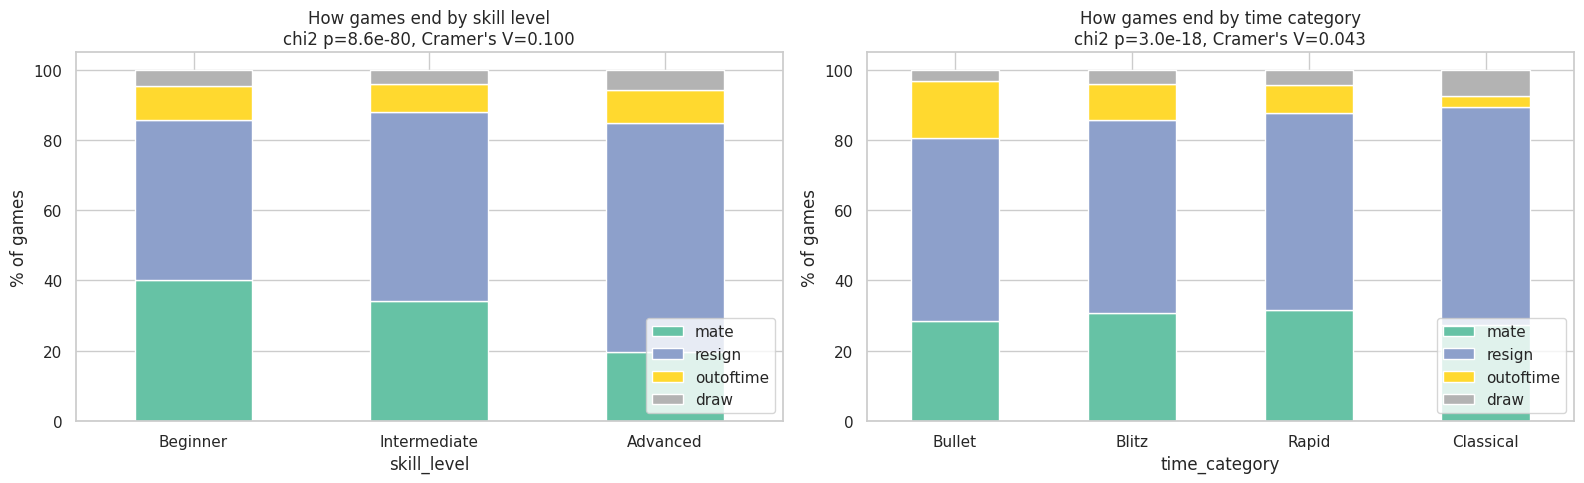

victory_status,mate,resign,outoftime,draw
time_category,,,,
Bullet,28.5,52.0,16.3,3.3
Blitz,30.8,54.8,10.3,4.1
Rapid,31.7,55.8,8.2,4.3
Classical,27.4,61.9,3.4,7.4


In [23]:
def cramers_v(ct):
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    return chi2, p, np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

status_order = ['mate', 'resign', 'outoftime', 'draw']
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for a, col in zip(ax, ['skill_level', 'time_category']):
    ct = pd.crosstab(clean[col], clean['victory_status'])[status_order]
    chi2, p, v = cramers_v(ct)
    (ct.div(ct.sum(axis=1), axis=0) * 100).plot(kind='bar', stacked=True, ax=a, colormap='Set2', rot=0)
    a.set_title(f"How games end by {col.replace('_', ' ')}\nchi2 p={p:.1e}, Cramer's V={v:.3f}")
    a.set_ylabel('% of games'); a.legend(title='', loc='lower right')
    print(f"{col}: chi2={chi2:.1f}, p={p:.2e}, Cramer's V={v:.3f}")
plt.tight_layout(); plt.show()

display((pd.crosstab(clean['time_category'], clean['victory_status'], normalize='index')[status_order] * 100).round(1))

**Reading this:** Both associations are statistically significant, but the effect sizes are small and **skill level matters more than time control** (Cramér's V of 0.10 vs 0.04).
- *Skill level:* beginners finish 40% of games with checkmate, advanced players only 20%. Advanced players resign far more (65% of their games vs 46% for beginners), meaning stronger players give up lost positions rather than play them out.
- *Time control:* the share of games lost on time falls from 16% in Bullet (only 123 games, so treat with care) to 10% in Blitz, 8% in Rapid and 3% in Classical. Classical also has the most draws (7.4%) and resignations (62%).

## 5. Do Elo ratings predict results? (calibration)

Elo theory predicts that the expected score for white is `1 / (1 + 10^(-diff/400))`. I compare that curve to what actually happened in 100-point rating-difference buckets. If the points follow the curve the ratings are well calibrated.

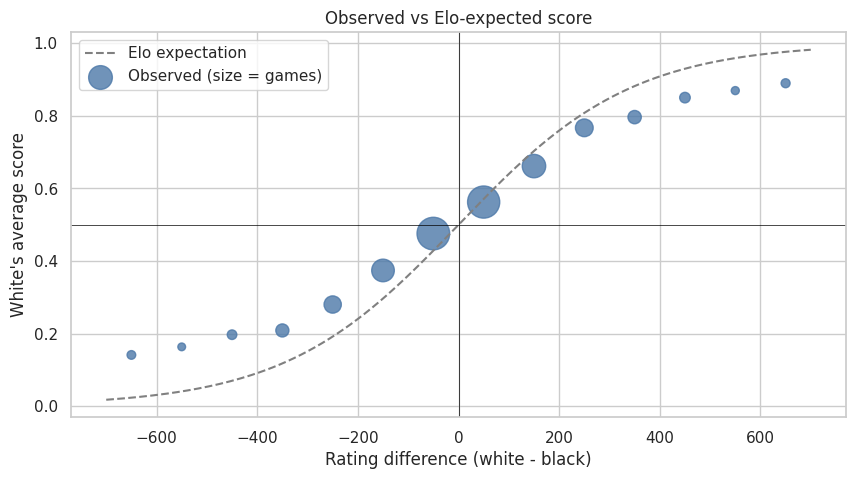

Brier score  Elo model: 0.2077 | always-50%: 0.2384 | improvement: 12.9%
Higher-rated player wins 65.3% of decisive games


,diff_bucket,games,actual,expected
0,"(-700, -600]",312,0.141,0.016
1,"(-600, -500]",248,0.163,0.043
2,"(-500, -400]",381,0.197,0.073
3,"(-400, -300]",712,0.209,0.122
4,"(-300, -200]",1239,0.280,0.198
5,"(-200, -100]",2123,0.374,0.305
6,"(-100, 0]",4415,0.476,0.441
7,"(0, 100]",4292,0.563,0.564
8,"(100, 200]",2278,0.662,0.697
9,"(200, 300]",1304,0.767,0.803


In [24]:
clean['expected_white'] = 1 / (1 + 10 ** (-clean['rating_diff'] / 400))

bucket_edges = list(range(-700, 701, 100))
clean['diff_bucket'] = pd.cut(clean['rating_diff'].clip(-699, 699), bucket_edges)
cal = clean.groupby('diff_bucket', observed=True).agg(
    games=('id', 'count'), actual=('white_score', 'mean'), expected=('expected_white', 'mean')).reset_index()
cal['mid'] = cal['diff_bucket'].apply(lambda i: i.mid)

plt.figure(figsize=(10, 5))
xs = np.linspace(-700, 700, 200)
plt.plot(xs, 1 / (1 + 10 ** (-xs / 400)), color='grey', ls='--', label='Elo expectation')
plt.scatter(cal['mid'], cal['actual'], s=cal['games'] / 8, color='#4C78A8', alpha=.8, label='Observed (size = games)')
plt.axhline(.5, color='black', lw=.5); plt.axvline(0, color='black', lw=.5)
plt.xlabel('Rating difference (white - black)'); plt.ylabel("White's average score")
plt.title('Observed vs Elo-expected score'); plt.legend(); plt.show()

# Brier score vs the naive "always 50%" baseline (draws counted as 0.5)
brier_elo = ((clean['expected_white'] - clean['white_score']) ** 2).mean()
brier_naive = ((0.5 - clean['white_score']) ** 2).mean()
print(f"Brier score  Elo model: {brier_elo:.4f} | always-50%: {brier_naive:.4f} | improvement: {1 - brier_elo / brier_naive:.1%}")
print(f"Higher-rated player wins {(clean.loc[clean.decisive & (clean.rating_diff != 0), 'is_upset'] == False).mean():.1%} of decisive games")
display(cal[['diff_bucket', 'games', 'actual', 'expected']].round(3))

**Reading this:** Near zero the observed results follow the Elo curve (and white scores a bit above it for small negative gaps, the first-move advantage again). But the real data is **much flatter than Elo theory** at large gaps: when white is 600 to 700 points *lower* rated, white still scores 14% where Elo predicts under 2%; when white is 600+ points higher rated it scores 89% where Elo predicts 98%. The Elo expectation improves on a coin-flip baseline by only about 13% (Brier score), and the higher-rated player wins 65% of decisive games. Plausible reasons (not tested here): provisional or out-of-date ratings, casual games, and games where the stronger player loses on time. In plain terms, **in this dataset ratings are a weaker predictor than the textbook formula says**, which also puts the Part 1 correlation of 0.36 in context.

## 6. Upsets

An **upset** is a decisive game won by the lower-rated player (draws and equal ratings are excluded). How likely are upsets as the rating gap widens, and are there patterns in who causes them?

,gap_band,games,upset_rate
0,0-50,4733,48.3%
1,50-100,3350,41.1%
2,100-200,4184,34.8%
3,200-300,2432,24.5%
4,300-500,2212,18.2%
5,500+,1129,12.2%


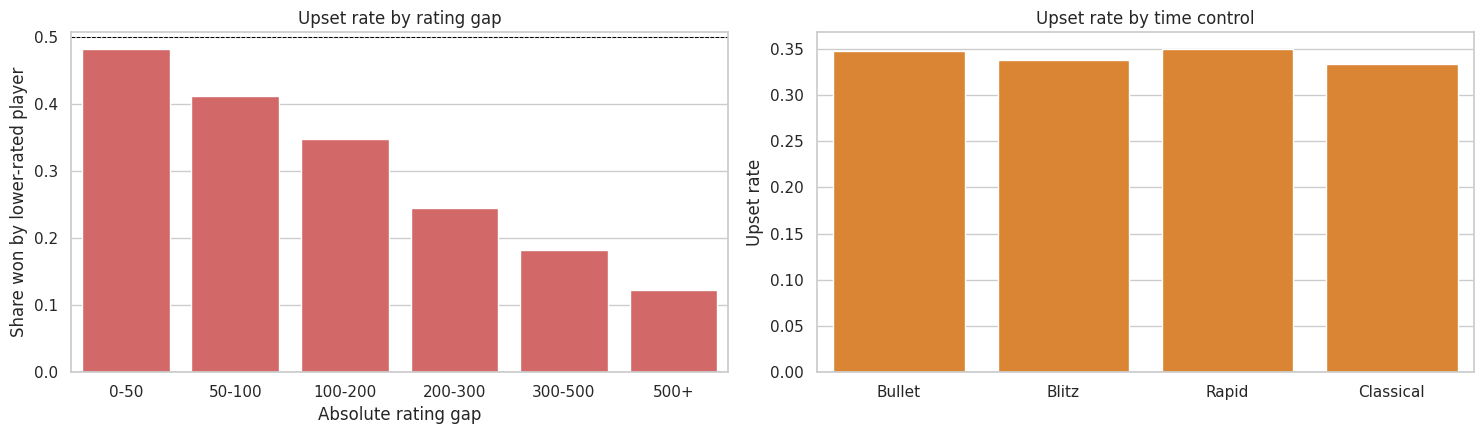

victory_status  mate  outoftime  resign
is_upset                               
False           33.6        8.0    58.4
True            31.2        9.5    59.2


In [25]:
dec = clean[clean['decisive'] & (clean['rating_diff'] != 0)].copy()
dec['gap_band'] = pd.cut(dec['abs_rating_diff'], [0, 50, 100, 200, 300, 500, 2000],
                         labels=['0-50', '50-100', '100-200', '200-300', '300-500', '500+'])
up = dec.groupby('gap_band', observed=True).agg(games=('id', 'count'), upset_rate=('is_upset', 'mean')).reset_index()
display(up.style.format({'upset_rate': '{:.1%}'}))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.barplot(data=up, x='gap_band', y='upset_rate', color='#E45756', ax=ax[0])
ax[0].set_title('Upset rate by rating gap'); ax[0].set_xlabel('Absolute rating gap'); ax[0].set_ylabel('Share won by lower-rated player')
ax[0].axhline(.5, color='black', ls='--', lw=.7)

up_tc = dec.groupby('time_category', observed=True)['is_upset'].mean().reset_index()
sns.barplot(data=up_tc, x='time_category', y='is_upset', color='#F58518', ax=ax[1])
ax[1].set_title('Upset rate by time control'); ax[1].set_ylabel('Upset rate'); ax[1].set_xlabel('')
plt.tight_layout(); plt.show()

# how do upsets typically end vs normal results?
print(pd.crosstab(dec['is_upset'], dec['victory_status'], normalize='index').round(3) * 100)

**Reading this:** About 35% of decisive games between unequal players are upsets. The upset rate falls steadily as the gap grows: about 48% within 50 points (nearly a coin flip), 41% for 51 to 100, 35% for 101 to 200, about 25% for 201 to 300, 18% for 301 to 500 and 12% beyond 500. Upset rates are almost identical across time controls (33% to 35%). Upsets end on time slightly more often than normal wins (9.5% vs 8.0%), but that gap is small, so I would not build a story on it.

## 7. Time controls

Which time controls are most popular and how do outcomes differ between them?

,time_category,games,avg_rating,median_turns,white_score,draw_rate,timeout_rate
0,Bullet,123,1593,44.000000,0.472,3.3%,16.3%
1,Blitz,3777,1599,56.000000,0.523,4.3%,10.3%
2,Rapid,14004,1594,56.000000,0.522,4.5%,8.2%
3,Classical,1209,1572,51.000000,0.531,7.4%,3.4%


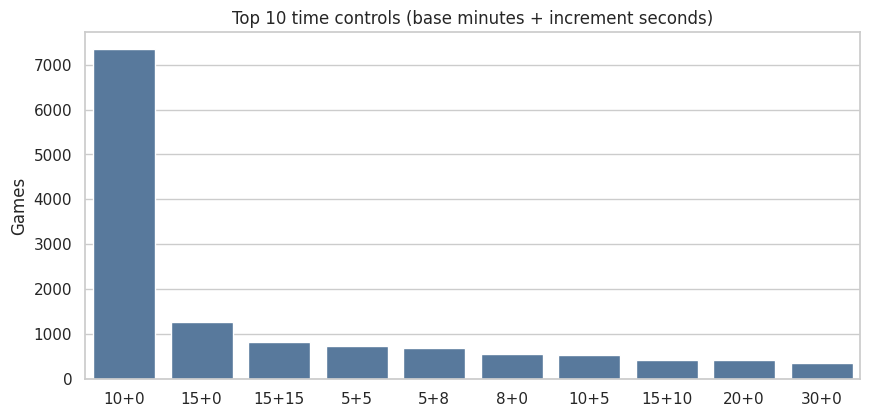

Kruskal-Wallis on white_score across time categories: H=1.62, p=0.654


In [26]:
tc = clean.groupby('time_category', observed=True).agg(
    games=('id', 'count'),
    avg_rating=('avg_rating', 'mean'),
    median_turns=('turns', 'median'),
    white_score=('white_score', 'mean'),
    draw_rate=('winner', lambda s: (s == 'draw').mean()),
    timeout_rate=('victory_status', lambda s: (s == 'outoftime').mean())).reset_index()
display(tc.style.format({'avg_rating': '{:.0f}', 'white_score': '{:.3f}', 'draw_rate': '{:.1%}', 'timeout_rate': '{:.1%}'}))

top_codes = clean['increment_code'].value_counts().head(10)
plt.figure(figsize=(10, 4.5))
sns.barplot(x=top_codes.index, y=top_codes.values, color='#4C78A8')
plt.title('Top 10 time controls (base minutes + increment seconds)'); plt.ylabel('Games'); plt.xlabel('')
plt.show()

# is the white-score different across time controls? (Kruskal-Wallis, non-parametric)
groups = [g['white_score'].values for _, g in clean.groupby('time_category', observed=True)]
h, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis on white_score across time categories: H={h:.2f}, p={p:.3f}")

**Reading this:** The dataset is mostly Rapid (73%) and Blitz (20%) games, plus 1,209 Classical and only 123 Bullet games, so Bullet conclusions are fragile. Skill level is similar across time controls (average rating 1570 to 1600). Timeouts fall steadily from Bullet to Classical, while draws are most common in Classical (7.4%). White's average score is not significantly different across time controls (Kruskal-Wallis p of about 0.65). The 10+0 and 15+0 formats dominate by volume.

## 8. Game length

Game length in turns, split by how the game ended and by skill level. A **Kruskal-Wallis** test is used because turn counts are heavily skewed.

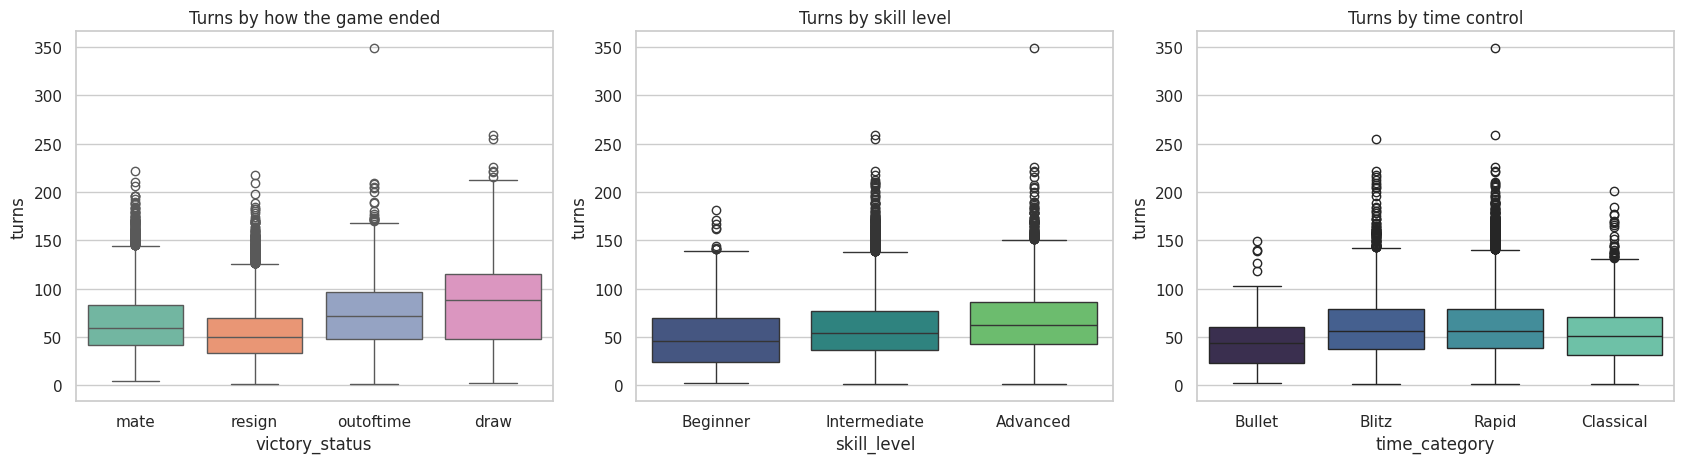

victory_status  Kruskal-Wallis H=  1011.2, p=6.68e-219
skill_level     Kruskal-Wallis H=   309.6, p=5.95e-68
time_category   Kruskal-Wallis H=    70.4, p=3.53e-15

Very short games (<=10 turns): 634 (3.3%); 70% ended by resignation, avg rating gap 266 vs 172 overall
Spearman(|rating diff|, turns) = -0.115, p=6.43e-57


In [27]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
sns.boxplot(data=clean, x='victory_status', y='turns', order=status_order, palette='Set2', ax=ax[0])
ax[0].set_title('Turns by how the game ended')
sns.boxplot(data=clean, x='skill_level', y='turns', palette='viridis', ax=ax[1]); ax[1].set_title('Turns by skill level')
sns.boxplot(data=clean, x='time_category', y='turns', palette='mako', ax=ax[2]); ax[2].set_title('Turns by time control')
plt.tight_layout(); plt.show()

for col in ['victory_status', 'skill_level', 'time_category']:
    g = [x['turns'].values for _, x in clean.groupby(col, observed=True)]
    h, p = stats.kruskal(*g)
    print(f"{col:15s} Kruskal-Wallis H={h:8.1f}, p={p:.2e}")

short = clean[clean['turns'] <= 10]
print(f"\nVery short games (<=10 turns): {len(short)} ({len(short)/len(clean):.1%}); "
      f"{(short['victory_status'] == 'resign').mean():.0%} ended by resignation, "
      f"avg rating gap {short['abs_rating_diff'].mean():.0f} vs {clean['abs_rating_diff'].mean():.0f} overall")

# does a bigger rating gap mean a shorter game?
rho, p = stats.spearmanr(clean['abs_rating_diff'], clean['turns'])
print(f"Spearman(|rating diff|, turns) = {rho:.3f}, p={p:.2e}")

**Reading this:** Draws are the longest games by far (median 88 turns), then games lost on time (72), checkmates (59) and resignations (50). Stronger players play longer games (median 46 turns for Beginners, 54 Intermediate, 62 Advanced). The correlation between rating gap and game length is weak but negative (Spearman about -0.11): bigger gaps mean slightly shorter games. Very short games (10 turns or fewer, 3.3% of the data) are mostly resignations (70%) with an average rating gap of 266 points vs 172 overall.

## 9. Openings with confidence intervals

Part 1 ranked openings by raw average score. With small samples that is misleading, so here every opening gets a 95% confidence interval and only openings with at least 100 games are compared. An opening is flagged as "significantly different from 50%" only when its interval excludes 0.5.

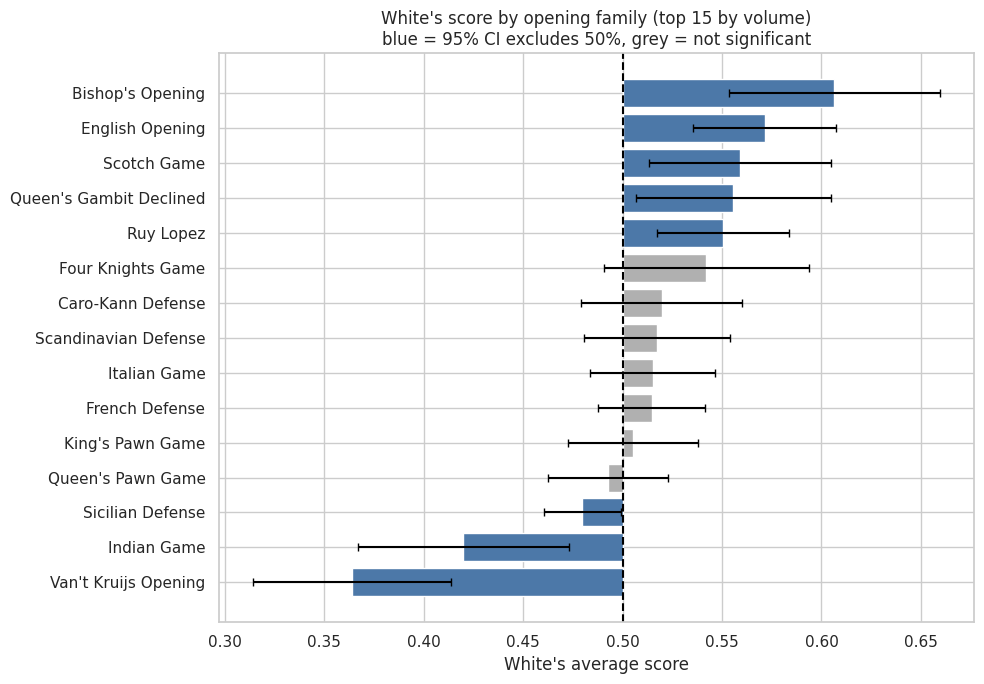

,opening_family,games,white_score,ci_low,ci_high,draw_rate,avg_rating,significant
149,Sicilian Defense,2473,0.480,0.461,0.499,4.9%,1674,True
54,French Defense,1258,0.515,0.488,0.542,5.0%,1628,False
130,Queen's Pawn Game,1012,0.493,0.462,0.523,4.4%,1596,False
69,Italian Game,926,0.515,0.484,0.547,5.0%,1588,False
80,King's Pawn Game,871,0.505,0.473,0.538,3.9%,1405,False
142,Ruy Lopez,812,0.550,0.517,0.584,5.9%,1634,True
47,English Opening,699,0.572,0.536,0.607,4.1%,1626,True
144,Scandinavian Defense,688,0.517,0.481,0.554,3.8%,1533,False
24,Caro-Kann Defense,559,0.520,0.479,0.560,5.2%,1667,False
146,Scotch Game,441,0.559,0.513,0.605,3.4%,1582,True


,eco_group_name,games,white_score,draw_rate,avg_turns
0,A - Flank openings,3773,0.504,4.8%,60.3
1,"B - Semi-open (e4, not e5)",5010,0.515,4.9%,61.0
2,C - Open games (e4 e5) / French,7279,0.538,4.3%,58.9
3,D - Closed / Queen's Gambit,2562,0.523,4.6%,62.9
4,E - Indian defences,489,0.514,6.3%,68.2


In [28]:
def opening_table(df, key, min_games=100):
    g = df.groupby(key).agg(games=('id', 'count'), white_score=('white_score', 'mean'),
                            white_wins=('winner', lambda s: (s == 'white').sum()),
                            draws=('winner', lambda s: (s == 'draw').sum()),
                            avg_rating=('avg_rating', 'mean'), avg_turns=('turns', 'mean')).reset_index()
    g = g[g['games'] >= min_games].copy()
    se = df.groupby(key)['white_score'].std().reindex(g[key]).values / np.sqrt(g['games'])
    g['ci_low'], g['ci_high'] = g['white_score'] - 1.96 * se, g['white_score'] + 1.96 * se
    g['significant'] = (g['ci_low'] > .5) | (g['ci_high'] < .5)
    g['draw_rate'] = g['draws'] / g['games']
    return g.sort_values('games', ascending=False)

fam = opening_table(clean, 'opening_family')
top = fam.head(15).sort_values('white_score')
plt.figure(figsize=(10, 7))
colors = np.where(top['significant'], '#4C78A8', '#B0B0B0')
plt.barh(top['opening_family'], top['white_score'] - .5, left=.5, color=colors,
         xerr=(top['ci_high'] - top['ci_low']) / 2, ecolor='black', capsize=3)
plt.axvline(.5, color='black', ls='--')
plt.title("White's score by opening family (top 15 by volume)\nblue = 95% CI excludes 50%, grey = not significant")
plt.xlabel("White's average score"); plt.tight_layout(); plt.show()

display(fam.head(15)[['opening_family', 'games', 'white_score', 'ci_low', 'ci_high', 'draw_rate', 'avg_rating', 'significant']]
        .style.format({'white_score': '{:.3f}', 'ci_low': '{:.3f}', 'ci_high': '{:.3f}', 'draw_rate': '{:.1%}', 'avg_rating': '{:.0f}'}))

eco = clean.groupby('eco_group_name').agg(games=('id', 'count'), white_score=('white_score', 'mean'),
                                          draw_rate=('winner', lambda s: (s == 'draw').mean()), avg_turns=('turns', 'mean')).reset_index()
display(eco.style.format({'white_score': '{:.3f}', 'draw_rate': '{:.1%}', 'avg_turns': '{:.1f}'}))

**Reading this:** Of the 15 most-played opening families, 8 are statistically different from 50% (blue bars) and 7 are not. Examples: **Bishop's Opening** (white score 0.61), **English Opening** (0.57) and **Scotch Game** (0.56) favour white, while the **Sicilian Defense** (0.48) favours black, consistent with Part 1. But watch the audience effect: the Van't Kruijs Opening (1. e3) scores a poor 0.36, yet its players average only about 1390 rating versus about 1675 for Sicilian players. Results partly reflect *who plays an opening*, not only how good the opening is, so any "best opening" claim needs that caveat.

## 10. Player-level analysis

Each game has two players, so I stack the data into one row per player per game, then summarise per player. Only players with at least 20 games are ranked to keep the results meaningful.

15,635 unique players | 392 with >=20 games | median games per player = 1 | top 1% of players account for 17.6% of player-games


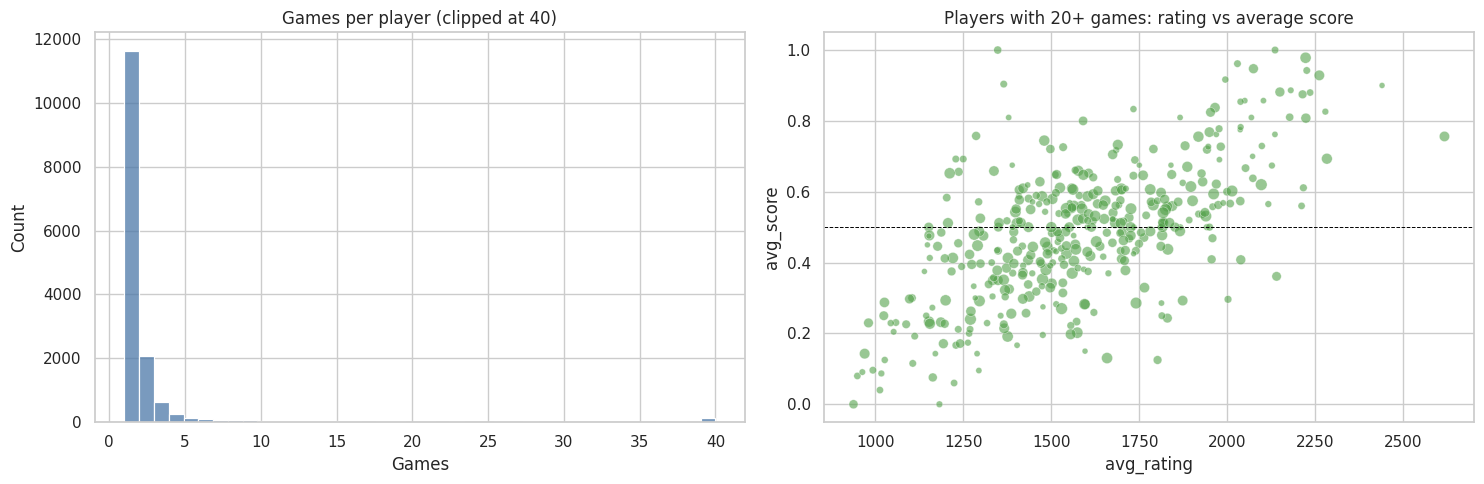

Most active players


,player_id,games,avg_rating,win_rate,avg_score,expected_score,overperformance
3806,dipset,51,1475.000,0.353,0.353,0.413,-0.061
2029,blazingdragon,50,1559.300,0.360,0.370,0.366,0.004
4686,fandm-lancaster,50,1270.040,0.240,0.240,0.200,0.040
7213,juncinmestrella,50,1824.640,0.520,0.550,0.539,0.011
7506,kevchod,50,1484.820,0.360,0.380,0.533,-0.153
11903,robixy,50,2096.820,0.600,0.620,0.694,-0.074
15458,zapala,50,1529.180,0.240,0.270,0.390,-0.120
3668,derspiegel,49,1740.898,0.265,0.286,0.364,-0.078


Biggest over-performers vs Elo expectation (>=20 games)


,player_id,games,avg_rating,win_rate,avg_score,expected_score,overperformance
11540,ranchowangdu,34,1497.324,0.647,0.721,0.217,0.504
6192,hus1972,33,1286.182,0.758,0.758,0.289,0.469
12861,siindbad,26,2136.000,1.000,1.000,0.615,0.385
8314,lolmens,27,1976.852,0.741,0.778,0.439,0.339
5449,gmanderson,24,1994.667,0.917,0.917,0.642,0.274
2974,christina-a-11,26,2029.154,0.962,0.962,0.692,0.269
4453,enricolord,34,1197.353,0.382,0.412,0.169,0.243
12235,saitama_opm,32,1619.094,0.625,0.641,0.401,0.240


Biggest under-performers


,player_id,games,avg_rating,win_rate,avg_score,expected_score,overperformance
360,aidenleahycrooks,37,1829.973,0.243,0.243,0.688,-0.445
2836,chesslearningpro,26,1546.423,0.500,0.538,0.855,-0.317
1260,arnomass,23,1475.783,0.174,0.196,0.500,-0.304
8010,lance5500,41,2617.537,0.756,0.756,0.989,-0.233
13739,tensors,24,1317.375,0.208,0.229,0.460,-0.231


Regular players: mean score as white 0.501 vs black 0.472 (paired t-test p=0.0006)


In [29]:
w = pd.DataFrame({'game_id': clean['id'], 'player_id': clean['white_id'], 'color': 'white', 'rating': clean['white_rating'],
                  'opp_rating': clean['black_rating'], 'score': clean['white_score'], 'turns': clean['turns'],
                  'status': clean['victory_status'], 'created_dt': clean['created_dt']})
b = pd.DataFrame({'game_id': clean['id'], 'player_id': clean['black_id'], 'color': 'black', 'rating': clean['black_rating'],
                  'opp_rating': clean['white_rating'], 'score': 1 - clean['white_score'], 'turns': clean['turns'],
                  'status': clean['victory_status'], 'created_dt': clean['created_dt']})
pg = pd.concat([w, b], ignore_index=True)
pg['expected'] = 1 / (1 + 10 ** ((pg['opp_rating'] - pg['rating']) / 400))

players = pg.groupby('player_id').agg(
    games=('game_id', 'count'), avg_rating=('rating', 'mean'), peak_rating=('rating', 'max'),
    win_rate=('score', lambda s: (s == 1).mean()), avg_score=('score', 'mean'), expected_score=('expected', 'mean'),
    games_as_white=('color', lambda s: (s == 'white').sum())).reset_index()
players['overperformance'] = players['avg_score'] - players['expected_score']
players['white_share'] = players['games_as_white'] / players['games']
regulars = players[players['games'] >= 20].copy()

print(f"{len(players):,} unique players | {len(regulars)} with >=20 games | "
      f"median games per player = {players['games'].median():.0f} | "
      f"top 1% of players account for {players.nlargest(max(1, len(players)//100), 'games')['games'].sum() / players['games'].sum():.1%} of player-games")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(players['games'].clip(upper=40), bins=40, ax=ax[0], color='#4C78A8')
ax[0].set_title('Games per player (clipped at 40)'); ax[0].set_xlabel('Games')
sns.scatterplot(data=regulars, x='avg_rating', y='avg_score', size='games', alpha=.6, ax=ax[1], legend=False, color='#54A24B')
ax[1].axhline(.5, color='black', ls='--', lw=.7); ax[1].set_title('Players with 20+ games: rating vs average score')
plt.tight_layout(); plt.show()

cols = ['player_id', 'games', 'avg_rating', 'win_rate', 'avg_score', 'expected_score', 'overperformance']
print('Most active players'); display(players.nlargest(8, 'games')[cols].round(3))
print('Biggest over-performers vs Elo expectation (>=20 games)'); display(regulars.nlargest(8, 'overperformance')[cols].round(3))
print('Biggest under-performers'); display(regulars.nsmallest(5, 'overperformance')[cols].round(3))

# does a player's score vary by colour? paired comparison for regulars
col_score = pg[pg['player_id'].isin(regulars['player_id'])].pivot_table(index='player_id', columns='color', values='score', aggfunc='mean').dropna()
t, p = stats.ttest_rel(col_score['white'], col_score['black'])
print(f"Regular players: mean score as white {col_score['white'].mean():.3f} vs black {col_score['black'].mean():.3f} (paired t-test p={p:.4f})")

**Reading this:** The dataset is a long tail. There are 15,635 players, the median player appears in just **1** game, and only 392 have 20 or more. The top 1% of players account for about 18% of all player-games. Among the 20+ game regulars, the over-performance column (actual score minus Elo-expected score) flags players whose rating probably lags their real strength (or whose rating was provisional), such as `ranchowangdu` and `hus1972`. With 20 to 50 games each these numbers are noisy, so use the list as a talking point rather than a verdict. Regulars also score better with white (0.50) than black (0.47), a paired difference that is statistically significant (p of about 0.0006).

## 11. Activity over time

When were games played? The data spans 2013-2017 but the volume is heavily concentrated in 2017, so I look at the monthly trend and the hour-of-day pattern for 2017 only.

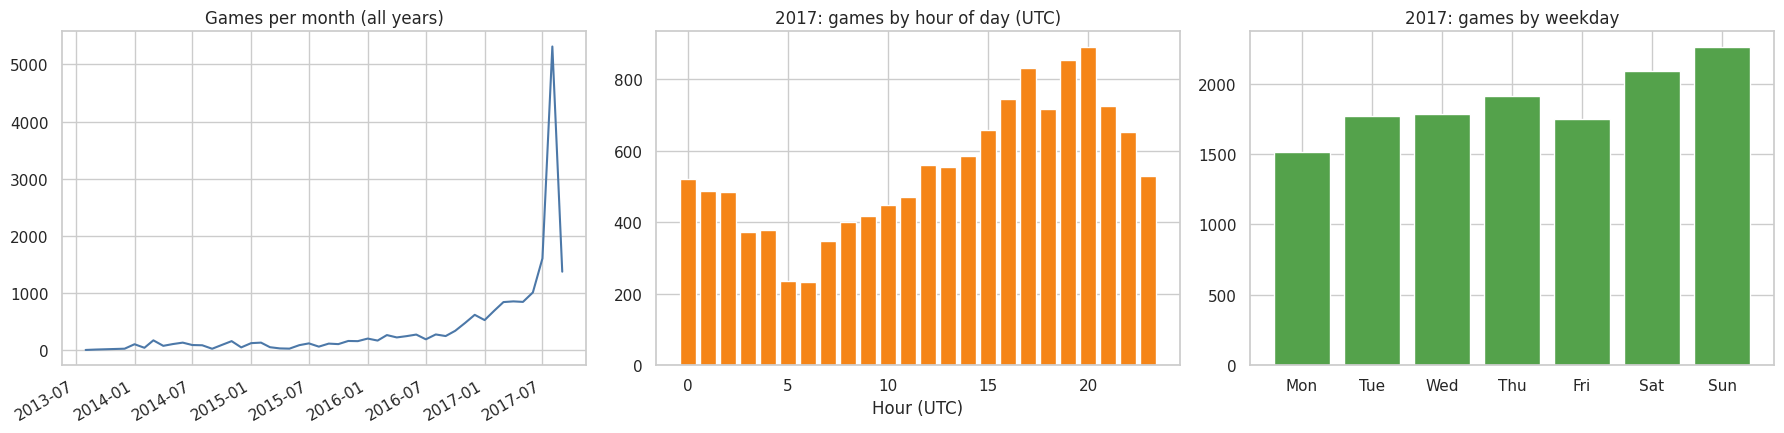

Share of all games played in 2017: 68.5%; in Aug 2017 alone: 27.8%
Timeout rate by hour (2017), min 6.0% / max 12.3%


In [30]:
monthly = clean.groupby('month').size()
c17 = clean[clean['year'] == 2017]
hourly = c17.groupby('hour_utc').agg(games=('id', 'count'), white_score=('white_score', 'mean'), timeout=('victory_status', lambda s: (s == 'outoftime').mean()))
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily = c17.groupby('weekday').size().reindex(order)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
monthly.plot(ax=ax[0], color='#4C78A8'); ax[0].set_title('Games per month (all years)'); ax[0].set_xlabel('')
ax[1].bar(hourly.index, hourly['games'], color='#F58518'); ax[1].set_title('2017: games by hour of day (UTC)'); ax[1].set_xlabel('Hour (UTC)')
ax[2].bar(range(7), daily.values, color='#54A24B'); ax[2].set_xticks(range(7)); ax[2].set_xticklabels([d[:3] for d in order]); ax[2].set_title('2017: games by weekday')
plt.tight_layout(); plt.show()

print(f"Share of all games played in 2017: {(clean['year'] == 2017).mean():.1%}; in Aug 2017 alone: {(clean['month'] == '2017-08-01').mean():.1%}")
print(f"Timeout rate by hour (2017), min {hourly['timeout'].min():.1%} / max {hourly['timeout'].max():.1%}")

**Reading this:** About 69% of all games are from 2017 and 28% are from August 2017 alone, which looks like a data-collection burst rather than organic growth, so **do not read the rising line as platform growth**. Within 2017, activity peaks in the evening UTC hours (about 16:00 to 21:00), and the timeout rate varies from about 6% to 12% by hour of day.

## 12. Predictive model

Finally, a simple model to quantify how much of the outcome rating difference explains. I use only **pre-game information** (ratings, rated flag, time control), because variables like number of turns or victory status are only known after the game ends and would leak the answer. Draws are excluded and the target is "white wins".

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve

m = clean[clean['decisive']].copy()
m['y'] = (m['winner'] == 'white').astype(int)
m['rated_int'] = m['rated'].astype(int)
feats_simple = ['rating_diff']
feats_full = ['rating_diff', 'avg_rating', 'rated_int', 'base_minutes', 'increment_sec']

cv = StratifiedKFold(5, shuffle=True, random_state=42)
res = {}
res['Always predict white (baseline)'] = (m['y'].mean(), 0.5)
for name, feats, model in [
    ('Logistic: rating_diff only', feats_simple, make_pipeline(StandardScaler(), LogisticRegression())),
    ('Logistic: + avg rating, rated, time control', feats_full, make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    ('Gradient boosting: same features', feats_full, GradientBoostingClassifier(random_state=42))]:
    acc = cross_val_score(model, m[feats], m['y'], cv=cv, scoring='accuracy').mean()
    auc = cross_val_score(model, m[feats], m['y'], cv=cv, scoring='roc_auc').mean()
    res[name] = (acc, auc)
display(pd.DataFrame(res, index=['accuracy (5-fold CV)', 'ROC-AUC (5-fold CV)']).T.round(3))

# interpretable coefficient: odds of a white win per +100 rating points
lr = LogisticRegression().fit(m[['rating_diff']] / 100, m['y'])
print(f"Odds ratio per +100 rating points for white: {np.exp(lr.coef_[0][0]):.2f}  (intercept odds = white advantage at equal rating: {np.exp(lr.intercept_[0]):.2f})")

,accuracy (5-fold CV),ROC-AUC (5-fold CV)
Always predict white (baseline),0.524,0.500
Logistic: rating_diff only,0.651,0.718
"Logistic: + avg rating, rated, time control",0.651,0.717
Gradient boosting: same features,0.651,0.716


Odds ratio per +100 rating points for white: 1.47  (intercept odds = white advantage at equal rating: 1.09)


**Reading this:** About two thirds of decisive games (65%) are called correctly by rating difference alone, with a ROC-AUC of about 0.72, vs 52% accuracy for always guessing "white wins". Adding average rating, rated flag and time control, or switching to gradient boosting, changes nothing (accuracy stays at 0.651), which tells us that the remaining uncertainty is mostly in-game events (blunders, time trouble) that pre-game data cannot capture. Each extra 100 rating points multiplies white's odds of winning by about 1.5, and at equal rating white's odds are about 1.09 to 1.

## 13. Key findings

1. **Data quality:** 945 duplicate games (4.7%) were silently inflating Part 1's counts, and at player level the top player's count was 3x too high (154 vs 49). Game duration is unusable (43% of games have zero duration), so turn count is used for game length.
2. **First-move advantage is real but small:** white wins 49.9% vs black 45.4%. Among decisive games white wins 52.4% (p of about 1.5e-10).
3. **Ratings predict outcomes, but less sharply than Elo theory says:** the higher-rated player wins only 65% of decisive games, and results are far flatter than the Elo curve at gaps over 400 points.
4. **Upsets decay with the gap:** 48% within 50 points, about 25% at 201 to 300 points and 12% beyond 500, with almost no difference between time controls.
5. **Skill level changes how games end more than time control does:** beginners checkmate 40% of the time vs 20% for advanced players, who resign 65% of the time.
6. **Time control shows up in timeouts and draws:** losses on time fall from 16% (Bullet, small sample) to 3% (Classical), while draws peak in Classical (7.4%).
7. **Opening rankings need context:** 8 of the top 15 opening families differ significantly from 50%, but results are tangled up with the rating of the players who choose them.
8. **Model ceiling:** rating difference alone gives about 65% accuracy (ROC-AUC 0.72), and extra pre-game features add nothing.

**Limitations:** a sample of selected users rather than all of Lichess; heavy concentration in 2017; no engine evaluations; repeat players mean games are not fully independent.

## 14. Export for Tableau

The cell below writes a **star schema** (one fact table plus dimension tables) into `./tableau/data/`. These CSVs are what the Tableau workbook loads. Splitting the data this way keeps the Tableau data model clean (Tableau *relationships* join the tables only when a view needs them), and lets filters, sort orders and hierarchies work properly.

| Table | Grain | Purpose |
|---|---|---|
| `fact_games` | one row per game | all measures are calculated from here (0/1 flag columns keep the calculated fields simple) |
| `dim_date` | one row per calendar day | time intelligence and date slicers |
| `dim_opening` | one row per opening name | opening family and ECO group hierarchy |
| `dim_time_control` | one row per time control code | category and sort order |
| `dim_skill_level` | one row per skill band | sort order |
| `player_games` | one row per player per game (2 rows per game) | exact distinct-player counts that respond to filters |
| `player_summary` | one row per player | player leaderboard page |
| `elo_calibration` | one row per rating-gap bucket | observed vs expected curve |

In [32]:
import os
out = './tableau/data'
os.makedirs(out, exist_ok=True)

# ---------- fact_games ----------
fact = clean.copy()
fact['game_date'] = fact['created_dt'].dt.strftime('%Y-%m-%d')
fact['rated'] = np.where(fact['rated'], 'Rated', 'Casual')
fact['winner_label'] = fact['winner'].str.capitalize()
fact['victory_status_label'] = fact['victory_status'].map({'mate': 'Checkmate', 'resign': 'Resignation', 'outoftime': 'Out of time', 'draw': 'Draw'})
fact['rating_gap_band'] = pd.cut(fact['abs_rating_diff'], [-1, 50, 100, 200, 300, 500, 5000],
                                 labels=['0-50', '51-100', '101-200', '201-300', '301-500', '500+']).astype(str)
fact['rating_gap_sort'] = fact['rating_gap_band'].map({'0-50': 1, '51-100': 2, '101-200': 3, '201-300': 4, '301-500': 5, '500+': 6})
fact['is_upset_eligible'] = (fact['decisive'] & (fact['rating_diff'] != 0)).astype(int)   # decisive game between unequal players
fact['is_upset'] = (fact['is_upset'] & (fact['is_upset_eligible'] == 1)).astype(int)
fact['is_decisive'] = fact['decisive'].astype(int)
fact['is_white_win'] = (fact['winner'] == 'white').astype(int)
fact['is_black_win'] = (fact['winner'] == 'black').astype(int)
fact['is_draw'] = (fact['winner'] == 'draw').astype(int)
fact['is_timeout'] = (fact['victory_status'] == 'outoftime').astype(int)
fact['is_resign'] = (fact['victory_status'] == 'resign').astype(int)
fact['is_mate'] = (fact['victory_status'] == 'mate').astype(int)
fact['expected_white_score'] = fact['expected_white'].round(4)

fact_cols = ['id', 'game_date', 'rated', 'turns', 'victory_status_label', 'winner_label', 'increment_code', 'white_id', 'white_rating',
             'black_id', 'black_rating', 'avg_rating', 'rating_diff', 'abs_rating_diff', 'rating_gap_band', 'rating_gap_sort', 'skill_level',
             'opening_name', 'opening_ply', 'first_move', 'black_response', 'white_score', 'expected_white_score',
             'is_white_win', 'is_black_win', 'is_draw', 'is_decisive', 'is_upset_eligible', 'is_upset', 'is_timeout', 'is_resign', 'is_mate', 'hour_utc']
fact = fact[fact_cols].rename(columns={'id': 'game_id', 'increment_code': 'time_control', 'victory_status_label': 'victory_status',
                                        'winner_label': 'winner', 'skill_level': 'skill_level'})
fact['skill_level'] = fact['skill_level'].astype(str)
fact['black_response'] = fact['black_response'].fillna('(no reply)')
fact.to_csv(f'{out}/fact_games.csv', index=False)

# ---------- dim_date ----------
dates = pd.date_range(clean['created_dt'].dt.normalize().min(), clean['created_dt'].dt.normalize().max(), freq='D')
dim_date = pd.DataFrame({'date': dates})
dim_date['date_key'] = dim_date['date'].dt.strftime('%Y-%m-%d')
dim_date['year'] = dim_date['date'].dt.year
dim_date['quarter'] = 'Q' + dim_date['date'].dt.quarter.astype(str)
dim_date['month_number'] = dim_date['date'].dt.month
dim_date['month_name'] = dim_date['date'].dt.strftime('%b')
dim_date['year_month'] = dim_date['date'].dt.strftime('%Y-%m')
dim_date['weekday_number'] = dim_date['date'].dt.dayofweek + 1
dim_date['weekday_name'] = dim_date['date'].dt.strftime('%a')
dim_date['is_weekend'] = np.where(dim_date['weekday_number'] >= 6, 'Weekend', 'Weekday')
dim_date = dim_date.drop(columns='date').rename(columns={'date_key': 'date'})
dim_date.to_csv(f'{out}/dim_date.csv', index=False)

# ---------- dim_opening ----------
dim_open = (clean.groupby('opening_name').agg(opening_eco=('opening_eco', 'first'), opening_family=('opening_family', 'first'),
                                              eco_group=('eco_group_name', 'first')).reset_index())
dim_open.to_csv(f'{out}/dim_opening.csv', index=False)

# ---------- dim_time_control ----------
dim_tc = clean.groupby('increment_code').agg(base_minutes=('base_minutes', 'first'), increment_sec=('increment_sec', 'first'),
                                             time_category=('time_category', 'first')).reset_index().rename(columns={'increment_code': 'time_control'})
dim_tc['estimated_minutes'] = (dim_tc['base_minutes'] + dim_tc['increment_sec'] * 40 / 60).round(1)
dim_tc['category_sort'] = dim_tc['time_category'].map({'Bullet': 1, 'Blitz': 2, 'Rapid': 3, 'Classical': 4}).astype(int)
dim_tc['time_category'] = dim_tc['time_category'].astype(str)
dim_tc.to_csv(f'{out}/dim_time_control.csv', index=False)

# ---------- dim_skill_level ----------
pd.DataFrame({'skill_level': ['Beginner', 'Intermediate', 'Advanced'], 'skill_sort': [1, 2, 3],
              'rating_band': ['under 1200', '1200 - 1800', 'over 1800']}).to_csv(f'{out}/dim_skill_level.csv', index=False)

# ---------- player_games (long format: one row per player per game) ----------
# A distinct player count across white AND black needs both players in a single column
# (Tableau cannot union two columns inside a view). This table is related to fact_games on game_id.
pg_white = pd.DataFrame({'game_id': fact['game_id'], 'player_id': fact['white_id'], 'color': 'White',
                         'player_rating': fact['white_rating'], 'opponent_rating': fact['black_rating'], 'player_score': fact['white_score']})
pg_black = pd.DataFrame({'game_id': fact['game_id'], 'player_id': fact['black_id'], 'color': 'Black',
                         'player_rating': fact['black_rating'], 'opponent_rating': fact['white_rating'], 'player_score': 1 - fact['white_score']})
pd.concat([pg_white, pg_black], ignore_index=True).to_csv(f'{out}/player_games.csv', index=False)

# ---------- player_summary ----------
players.assign(is_regular=np.where(players['games'] >= 20, 'Regular (20+ games)', 'Casual (<20 games)'), win_rate=players['win_rate'].round(4), avg_score=players['avg_score'].round(4), expected_score=players['expected_score'].round(4),
               overperformance=players['overperformance'].round(4), avg_rating=players['avg_rating'].round(0),
               white_share=players['white_share'].round(4)).drop(columns=['games_as_white']).to_csv(f'{out}/player_summary.csv', index=False)

# ---------- elo_calibration ----------
cal_out = cal[['diff_bucket', 'mid', 'games', 'actual', 'expected']].copy()
cal_out['diff_bucket'] = cal_out['diff_bucket'].astype(str)
cal_out.rename(columns={'mid': 'bucket_midpoint', 'actual': 'actual_white_score', 'expected': 'expected_white_score'}).round(4).to_csv(f'{out}/elo_calibration.csv', index=False)

for f in sorted(os.listdir(out)):
    d_ = pd.read_csv(f'{out}/{f}')
    print(f"{f:24s} {len(d_):>7,} rows x {d_.shape[1]:>2} cols")

dim_date.csv               1,480 rows x  9 cols
dim_opening.csv            1,477 rows x  4 cols
dim_skill_level.csv            3 rows x  3 cols
dim_time_control.csv         400 rows x  6 cols
elo_calibration.csv           14 rows x  5 cols
fact_games.csv            19,113 rows x 33 cols
player_summary.csv        15,635 rows x 10 cols


In [33]:
# Sanity checks: the Tableau dashboard should show these exact KPI values on its first page
f = pd.read_csv('./tableau/data/fact_games.csv')
assert f['game_id'].is_unique
pg = pd.read_csv('./tableau/data/player_games.csv')
assert len(pg) == 2 * len(f) and pg['game_id'].isin(f['game_id']).all()
checks = {
    'Total games': len(f),
    'White win %': f['is_white_win'].mean(),
    'Black win %': f['is_black_win'].mean(),
    'Draw %': f['is_draw'].mean(),
    'Avg rating': f['avg_rating'].mean(),
    'Avg turns': f['turns'].mean(),
    'Upset rate (decisive, unequal)': f['is_upset'].sum() / f['is_upset_eligible'].sum(),
    'Timeout %': f['is_timeout'].mean(),
    'Unique players': pg['player_id'].nunique(),
}
display(pd.Series(checks, name='expected KPI value').to_frame().round(4))

,expected KPI value
Total games,19113.0000
White win %,0.4994
Black win %,0.4541
Draw %,0.0465
Avg rating,1593.6728
Avg turns,60.5138
"Upset rate (decisive, unequal)",0.3467
Timeout %,0.0836
Unique players,15635.0000


**Next step:** open Tableau Desktop (or the free Tableau Public) and follow `tableau/BUILD_GUIDE.md`, which loads these CSVs, sets up the relationships, adds the calculated fields and lays out the dashboards.